# Optimización de hiperparámetros para predecir la popularidad de canciones de Spotify
## Random Search, Grid Search, ensambles y validación cruzada

| | |
|---|---|
| **Asignatura** | MLY1101 Machine Learning |
| **Evaluación** | Parcial Nro. 3: presentación y defensa técnica del proyecto |
| **Equipo** | Grupo 5: Cristian Romero y Rolando Paredes |
| **Caso** | C: inteligencia musical y predicción de popularidad de canciones (Spotify Tracks) |
| **Metodología** | CRISP-DM, fase 4 (modelado con ajuste de hiperparámetros) y fase 5 (evaluación) |
| **Entrada** | Lo que exporta la EV2 en `data/processed/ev2/` (las tablas ya preprocesadas de cada modelo) y el objetivo, los identificadores y el género de la EV1 (`data/processed/ev1/`) |
| **Informe** | `README.md` resume este notebook; aquí está el respaldo de cada cifra |

### Índice

1. Objetivo, criterios de éxito e hipótesis de partida
2. Entrada: las tablas preprocesadas de la EV2
3. Los tres modelos y sus hiperparámetros
4. Punto de partida: hiperparámetros por defecto
5. Optimización: primero Random Search y después Grid Search
6. Evaluación en prueba de los finalistas
7. Experimentos: pérdida absoluta y artista
8. Selección de la solución y tabla comparativa final
9. Errores e interpretación de la solución final
10. Conclusiones, limitaciones y recomendaciones
11. Reflexión a nivel de proyecto
12. Reproducibilidad

---
# 1. Objetivo, criterios de éxito e hipótesis de partida

## 1.1 Qué se busca

Este notebook es un documento separado de la EV1 y de la EV2. No repite el EDA ni vuelve a probar cómo preparar los datos: eso ya se resolvió en la EV2, donde se comprobó que **la preparación dedicada a cada modelo es mejor** que una preparación única. Aquí se parte de las tablas que esa etapa dejó listas para cada modelo (sección 2) y se hace solo lo que corresponde a esta unidad: **buscar los hiperparámetros** de los mismos tres modelos (Ridge, Random Forest y XGBoost) y medir si mejoran frente a los valores por defecto. La pregunta es una sola:

> **Con los mismos tres modelos y los mismos datos preparados, ¿se pueden encontrar hiperparámetros que cumplan los seis criterios de éxito, y qué cuesta lograrlo?**

Es un trabajo de investigación: cada decisión se prueba antes de darse por buena, cada hipótesis se escribe antes de medir y se responde después con los resultados, y se anota también lo que no funciona.

## 1.2 Criterios de éxito

Son los mismos que se fijaron antes de modelar y no se modifican para que alguno "pase".

| # | Criterio | Umbral |
|---|---|---|
| 1 | R² | ≥ 0,40 |
| 2 | RMSE | ≤ 15,51 (77% del RMSE de la línea base) |
| 3 | MAE | ≤ 13,46 (80% del MAE de la línea base) |
| 4 | Brecha de R² entre entrenamiento y evaluación | ≤ 0,05 |
| 5 | MAE en canciones de popularidad ≥ 70 | ≤ 20 |
| 6 | Brecha de MAE entre cuartiles de género | ≤ 5 |

**Cómo se usan sin mirar la prueba.** Mientras se busca, cada combinación de hiperparámetros se mide con los mismos seis criterios pero **en validación cruzada** (sobre los folds que el modelo no vio). La prueba no participa en ninguna decisión de búsqueda: se usa una sola vez por candidato, al final, para confirmar. Si se ajustara mirando la prueba, sus resultados dejarían de ser una estimación honesta de lo que pasará con canciones nuevas.

**Regla para elegir una combinación.** Gana la que cumple más criterios; si dos cumplen los mismos, gana la de menor MAE de validación. Se fija antes de buscar porque los criterios tiran en direcciones distintas (por ejemplo, bajar la brecha de R² obliga a podar los modelos, y eso suele subir el error). Como un solo contador de criterios es una regla tosca, junto al ganador de la regla se lleva siempre a la prueba el candidato de **menor MAE**.

**La métrica principal es el MAE, y la pérdida del modelo es otra cosa.** Comparamos candidatos con el MAE como métrica principal porque así lo fijamos en la EV1: se lee directo en puntos de popularidad y no se deja dominar por unos pocos errores enormes. Eso no obliga a que el modelo minimice el MAE al entrenar: la función de pérdida (lo que el modelo optimiza) y la métrica de comparación (con la que lo juzgamos) son cosas distintas. Además, el RMSE y el R² también cuentan en la regla, porque son dos de los seis criterios, y el MAE solo desempata. Mirando el RMSE en lugar del MAE, el orden de los candidatos y las conclusiones son los mismos.

## 1.3 Hipótesis de partida

Se escriben antes de medir. Las dos de esta sección salen de lo que dejó la EV2; las demás se plantean **en el punto del notebook donde nacen**, justo antes de medirlas, y cada una se responde después de ver sus resultados.

| # | Hipótesis (planteada como pregunta) | Dónde se responde |
|---|---|---|
| H1 | ¿Ajustar los hiperparámetros mejora el error de validación de los tres modelos respecto de sus valores por defecto, más que el ruido entre folds? | 5.6 y 6 |
| H2 | ¿Algún modelo ajustado llega a cumplir los seis criterios de éxito? | 5.6, 6 y 8 |

---
# 2. Entrada: las tablas preprocesadas de la EV2

## 2.1 Librerías, rutas y GPU

Semilla única (42) y rutas relativas a la raíz del proyecto. Las búsquedas guardan su resultado en `data/processed/ev3/busquedas/`; si el archivo existe, el notebook lo lee en lugar de repetir la búsqueda (con `RECALCULAR = True` se repite completa). No se silencia ningún aviso de las librerías.

In [1]:
import os, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import display

import sklearn, xgboost
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBRegressor

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 90)

SEMILLA = 42
np.random.seed(SEMILLA)

# Raíz del proyecto: se sube desde la carpeta actual hasta encontrar data/raw
RAIZ = Path.cwd()
while not (RAIZ / 'data' / 'raw').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
CARPETA = RAIZ / 'data' / 'processed'
EV1_DIR = CARPETA / 'ev1'                    # lo que exporta la EV1 (objetivo, identificadores y género)
EV2_DIR = CARPETA / 'ev2'                    # lo que exporta la EV2
BUSQUEDAS = CARPETA / 'ev3' / 'busquedas'    # resultado de cada búsqueda
IMAGENES = RAIZ / 'ev3' / 'images'
MODELOS = RAIZ / 'models'
for d in (BUSQUEDAS, IMAGENES, MODELOS):
    os.makedirs(d, exist_ok=True)

RECALCULAR = False   # True repite todas las búsquedas (puede tardar más de una hora); False lee las guardadas

# ---------- GPU: XGBoost entrena y busca en la tarjeta gráfica si hay CUDA
gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], capture_output=True, text=True).stdout.strip()
try:
    XGBRegressor(device='cuda', n_estimators=2).fit(np.random.rand(50, 3), np.random.rand(50))
    DISPOSITIVO = 'cuda'
except Exception as e:
    DISPOSITIVO = 'cpu'
    print('XGBoost no pudo usar CUDA:', type(e).__name__)
N_HILOS_RF = 6                                # Random Forest solo corre en CPU: se limita a 6 de los 12 hilos

print('Python / pandas', pd.__version__, '/ scikit-learn', sklearn.__version__, '/ xgboost', xgboost.__version__)
print('GPU:', gpu or 'no detectada', '| XGBoost entrena en:', DISPOSITIVO, '| hilos de Random Forest:', N_HILOS_RF)

Python / pandas 3.0.5 / scikit-learn 1.9.1 / xgboost 3.4.1
GPU: NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB | XGBoost entrena en: cuda | hilos de Random Forest: 6


**Nota.** XGBoost y su búsqueda de hiperparámetros corren en la GPU (`device='cuda'`). Ridge y Random Forest de scikit-learn no tienen versión para GPU, así que usan la CPU; para no saturarla, Random Forest se limita a 6 de los 12 hilos. En las búsquedas de XGBoost se prueba **un candidato a la vez**, porque varios procesos peleando por una misma GPU no la hacen más rápida.

## 2.2 Carga y comprobaciones

La EV2 exporta (sección 12.5 de su notebook) una tabla de entrenamiento y una de prueba **ya preprocesadas para cada modelo**, con la preparación final que ella misma probó hipótesis por hipótesis: Ridge con Yeo-Johnson, estandarización y género por media de popularidad (16 columnas); Random Forest con el género en one-hot (128 columnas); XGBoost con el género como categoría nativa (15 variables más el género). Se usan tal cual, sin volver a transformar nada. También exporta los mismos 5 folds de validación cruzada, los criterios de éxito y las métricas de los tres modelos con hiperparámetros por defecto, que son el punto de comparación.

In [2]:
leer = lambda ruta: pd.read_csv(ruta)

entrega = joblib.load(EV2_DIR / 'preprocesado_ev2.joblib')
GENEROS = entrega['generos']
XTR = {t: entrega['tablas'][t]['X_train'].reset_index(drop=True) for t in entrega['tablas']}    # tabla de entrenamiento de cada modelo
XTE = {t: entrega['tablas'][t]['X_test'].reset_index(drop=True) for t in entrega['tablas']}     # tabla de prueba de cada modelo

y_train, y_test = leer(EV1_DIR / 'y_train.csv')['popularity'], leer(EV1_DIR / 'y_test.csv')['popularity']
ids_train, ids_test = leer(EV1_DIR / 'ids_train.csv'), leer(EV1_DIR / 'ids_test.csv')
GENERO_TR = leer(EV1_DIR / 'X_train_base.csv')['track_genre']        # el género de cada canción, como texto (solo sirve para medir la equidad)
GENERO_TE = leer(EV1_DIR / 'X_test_base.csv')['track_genre']
with open(EV2_DIR / 'criterios_exito.json', encoding='utf-8') as f:
    crit = json.load(f)
with open(EV2_DIR / 'metricas_ev2.json', encoding='utf-8') as f:
    met_ev2 = json.load(f)

# Los mismos 5 folds agrupados por canción de la EV2
fold_id = leer(EV2_DIR / 'folds_validacion_cruzada.csv')['fold'].values
FOLDS = [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(5)]

compartidas = set(ids_train['grupo_cancion']) & set(ids_test['grupo_cancion'])
grupos_en_dos_lados = [k for k, (a, b) in enumerate(FOLDS) if set(ids_train['grupo_cancion'].iloc[a]) & set(ids_train['grupo_cancion'].iloc[b])]
print(f'Entrenamiento: {len(y_train):,} canciones | Prueba: {len(y_test):,}')
for t in XTR:
    print(f'  {t:6s} entrenamiento {XTR[t].shape} | prueba {XTE[t].shape} | nulos: {int(XTR[t].isnull().sum().sum())} | columna del género: {XTR[t]["track_genre"].dtype if "track_genre" in XTR[t] else "en one-hot"}')
print('Canciones en entrenamiento y prueba a la vez:', len(compartidas))
print('Folds con canciones repetidas entre entrenamiento y validación:', grupos_en_dos_lados or 'ninguno')
print('Tamaño de validación por fold:', [len(b) for _, b in FOLDS])
print('Línea base de la EV2 (predice siempre la media):', {k: round(v, 3) for k, v in crit['linea_base'].items()})

Entrenamiento: 68,704 canciones | Prueba: 17,155
  ridge  entrenamiento (68704, 16) | prueba (17155, 16) | nulos: 0 | columna del género: float64
  rf     entrenamiento (68704, 128) | prueba (17155, 128) | nulos: 0 | columna del género: en one-hot
  xgb    entrenamiento (68704, 16) | prueba (17155, 16) | nulos: 0 | columna del género: category
Canciones en entrenamiento y prueba a la vez: 0
Folds con canciones repetidas entre entrenamiento y validación: ninguno
Tamaño de validación por fold: [13741, 13741, 13741, 13741, 13740]
Línea base de la EV2 (predice siempre la media): {'MAE': 16.825, 'RMSE': 20.147, 'R2': -0.0}


**Nota.** Se comprueban cuatro cosas antes de seguir: que las tablas de cada modelo tengan las mismas canciones que `y_train` y `y_test` (mismo número de filas) y ningún nulo; que ninguna canción esté en entrenamiento y prueba a la vez; que ninguna canción quede a los dos lados de un fold (por eso los folds son agrupados por canción: dos versiones de una misma canción son casi idénticas, y si quedaran separadas el modelo "reconocería" la canción y el error se vería menor del real); y que la línea base venga de la EV2 y no se recalcule.

## 2.3 Los criterios de éxito como medida de cada combinación

Cada combinación de hiperparámetros se evalúa con **una sola función** que calcula todo lo necesario para los seis criterios sobre los folds de validación. Es la única función que se define de antemano, porque se usa en todas las búsquedas y repetirla en cada una sería más largo y más propenso a errores.

Los cuartiles de género se arman como en la EV2: los géneros se ordenan por su popularidad media en el entrenamiento y las canciones se reparten en cuatro cuartiles.

In [3]:
UMBRALES = {'R2': 0.40, 'RMSE': crit['RMSE prueba (maximo)'], 'MAE': crit['MAE prueba (maximo)'],
            'brecha_R2': 0.05, 'MAE_exitos': 20.0, 'brecha_cuartiles': 5.0}
CORTE_EXITO = crit['corte de exito']
MEDIA_GENERO = y_train.groupby(GENERO_TR).mean()          # popularidad media de cada género (solo entrenamiento)

def medidas(p, genero, y):
    # Las cinco medidas que necesitan los criterios, a partir de unas predicciones p (genero = género de cada canción, solo para los cuartiles)
    p, y = np.asarray(p), np.asarray(y)
    e = np.abs(y - p)
    cuartil = pd.qcut(pd.Series(np.asarray(genero)).map(MEDIA_GENERO).values, q=4, labels=False)
    por_cuartil = pd.Series(e).groupby(cuartil).mean()
    return {'MAE': e.mean(), 'RMSE': np.sqrt(np.mean((y - p) ** 2)), 'R2': r2_score(y, p),
            'MAE_exitos': e[y >= CORTE_EXITO].mean(), 'brecha_cuartiles': por_cuartil.max() - por_cuartil.min()}

def puntuar(modelo, X, y):
    # Se usa como scoring en las búsquedas: una sola predicción por fold. X conserva el índice original, que sirve para buscar el género
    return medidas(modelo.predict(X), GENERO_TR.iloc[X.index], y)

pd.DataFrame([UMBRALES], index=['umbral'])

,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
umbral,0.400,15.513,13.460,0.050,20.000,5.000


**Nota.** `puntuar` entrega las cinco medidas con una sola llamada a `predict` por fold, y se usa tal cual en cada búsqueda. El criterio 4 (brecha de R²) sale de comparar el R² en entrenamiento con el de validación, que la búsqueda ya guarda con `return_train_score=True`. Una precisión: el género de cada canción se asigna a su cuartil con la media de **todo** el entrenamiento; solo afecta cómo se agrupan los errores al medir el criterio 6, no el modelo ni su entrenamiento.

---
# 3. Los tres modelos y sus hiperparámetros

## 3.1 Parámetros e hiperparámetros

| | Parámetros | Hiperparámetros |
|---|---|---|
| Quién los fija | El modelo, al entrenar | Quien diseña el experimento, antes de entrenar |
| Ejemplos aquí | Coeficientes de Ridge; cortes y valores de hoja de cada árbol | `alpha`; `max_depth`; `learning_rate` |
| Cómo se obtienen | Minimizando el error en el entrenamiento | Probando valores y midiendo en validación (nunca en entrenamiento) |

Los valores por defecto de una librería no conocen este problema. Se busca el punto entre el subajuste (modelo demasiado simple: error alto en todo) y el sobreajuste (modelo que memoriza el entrenamiento y falla con datos nuevos): el compromiso entre sesgo y varianza.

## 3.2 Diferencias técnicas entre los tres modelos

| | **Ridge** | **Random Forest** | **XGBoost** |
|---|---|---|---|
| Familia | Modelo lineal con castigo | Ensamble de árboles en paralelo: **bagging** | Ensamble de árboles en secuencia: **boosting** |
| Cómo aprende | Minimiza el error cuadrático más `alpha` por la suma de los coeficientes al cuadrado | Cada árbol se entrena con una muestra al azar (con reemplazo) y en cada corte mira solo algunas variables; la predicción es el promedio | Cada árbol nuevo corrige el error de los anteriores y se suma con un peso pequeño (`learning_rate`) |
| Qué reduce | Varianza, a costa de sesgo | **Varianza**: promediar árboles distintos compensa sus errores | **Sesgo**: cada árbol agrega lo que faltaba |
| Datos que recibe (EV2) | Variables asimétricas con Yeo-Johnson y estandarizadas; género por media de popularidad | Variables sin transformar; género en one-hot | Variables sin transformar; género como categoría nativa |
| Riesgo principal | No capta relaciones no lineales | Cada árbol memoriza su muestra | Sobreajuste al ruido si hay muchos árboles o son muy profundos |
| Dónde corre | CPU | CPU (no existe versión para GPU en scikit-learn) | **GPU** |
| Dificultad de ajuste | Una dimensión | Moderada | Alta: muchos hiperparámetros que interactúan |

## 3.3 Hiperparámetros que se ajustan y por qué esos rangos

Los rangos salen de dos fuentes: la documentación de cada modelo y el diagnóstico de la EV2 (dónde estaba el sobreajuste). No se usan rangos infinitos: cada combinación cuesta 5 entrenamientos (uno por fold), y una buena búsqueda empieza acotando con criterio.

| Modelo | Hiperparámetro | Qué controla | Por qué este rango |
|---|---|---|---|
| Ridge | `alpha` (10⁻³ a 10³, escala logarítmica) | Cuánto se encogen los coeficientes | Un solo hiperparámetro; su efecto es multiplicativo, por eso la escala logarítmica |
| Random Forest | `max_depth` | Profundidad máxima de cada árbol | La EV2 mostró árboles que memorizan (sin límite): se prueban límites y también sin límite |
| | `min_samples_leaf` | Mínimo de canciones por hoja | Hojas más grandes promedian más y bajan la varianza |
| | `max_features` | Fracción de variables que mira cada corte | Con 128 columnas (113 de género) mirar menos variables vuelve los árboles más distintos entre sí |
| | `max_samples` | Fracción de filas de cada árbol | Muestras más chicas también diversifican los árboles |
| XGBoost | `n_estimators` y `learning_rate` | Número de árboles y tamaño de su paso | Van juntos: pasos más chicos necesitan más árboles |
| | `max_depth` | Profundidad de cada árbol | Árboles poco profundos son los aprendices débiles del boosting |
| | `min_child_weight` | Peso mínimo en una hoja | Evita hojas con pocas canciones |
| | `subsample`, `colsample_bytree` | Fracción de filas y de variables por árbol | Aleatoriedad que reduce el sobreajuste |
| | `reg_lambda`, `reg_alpha` | Regularización L2 y L1 de las hojas | Penalizan valores de hoja extremos |

Dos decisiones de diseño que conviene dejar dichas. Primero, **la función de pérdida de XGBoost no se busca aquí**: se deja la cuadrática por defecto (que optimiza R² y RMSE) y se prueba la absoluta (que optimiza el MAE) como un experimento aparte en la sección 7, con su propia hipótesis. Segundo, Random Forest usa **100 árboles** en todas las búsquedas, igual que la EV2: se compara el efecto de los demás hiperparámetros, no el de agregar árboles.

---
# 4. Punto de partida: hiperparámetros por defecto

Antes de buscar hay que saber desde dónde se parte, y ese punto de partida son los hiperparámetros por defecto, los mismos de la EV2. **Los volvemos a medir**, y no solo copiamos sus cifras, por una razón práctica: la EV2 exportó para la validación solo el MAE, el RMSE y el ruido entre folds, y la búsqueda necesita, para cada candidato, las seis medidas de los criterios de éxito (incluidas la brecha de R² entre entrenamiento y validación, el error en éxitos y la equidad por género). Para que los valores por defecto entren en la misma tabla que los demás candidatos, con las mismas columnas, se miden con la misma maquinaria: un `GridSearchCV` con una sola combinación, la de fábrica. Es barato (segundos en Ridge y XGBoost y unos minutos en Random Forest). Como control, al final de la sección se compara con lo que midió la EV2: deben coincidir.

In [4]:
# ---------- Los tres modelos, listos para recibir las tablas de la EV2 (no hay preprocesador: los datos ya vienen preparados)
def armar(tipo, **fijos):
    if tipo == 'ridge':
        return Ridge(**fijos)
    if tipo == 'rf':
        return RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=N_HILOS_RF, **fijos)
    if tipo == 'xgb':
        return XGBRegressor(enable_categorical=True, device=DISPOSITIVO, tree_method='hist', random_state=SEMILLA, n_jobs=1, **fijos)

NOMBRES = {'ridge': 'Ridge', 'rf': 'Random Forest', 'xgb': 'XGBoost'}
for t in NOMBRES:
    print(f'{NOMBRES[t]:14s}', armar(t))

Ridge          Ridge()
Random Forest  RandomForestRegressor(n_jobs=6, random_state=42)
XGBoost        XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device='cuda', early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=1, num_parallel_tree=None, ...)


**Nota.** `armar()` devuelve el modelo con sus valores por defecto más lo que se quiera dejar fijo (en la sección 7, por ejemplo, la función de pérdida). No lleva preprocesador porque la EV2 ya entregó cada tabla preparada para su modelo. `n_jobs=1` en XGBoost es deliberado: el cálculo pesado va a la GPU y no tiene sentido repartir hilos de CPU para además cargarla. El aviso que XGBoost muestra al predecir (datos en CPU y modelo en GPU) solo indica que la predicción usa un camino algo más lento; no cambia ningún resultado y no se silencia.

In [5]:
# ---------- Una búsqueda: guarda y lee su resultado, y le agrega los criterios de éxito (se usa en todas las secciones siguientes)
def nativo(v):
    return v.item() if hasattr(v, 'item') else v

def buscar(etiqueta, buscador, X, **ajuste):
    ruta = BUSQUEDAS / f'{etiqueta}.csv'
    if ruta.exists() and not RECALCULAR:
        res = pd.read_csv(ruta)
    else:
        t0 = time.time()
        buscador.fit(X, y_train, **ajuste)
        res = pd.DataFrame(buscador.cv_results_)
        res['params_json'] = [json.dumps({k: nativo(v) for k, v in p.items()}) for p in buscador.cv_results_['params']]
        res['segundos_total'] = time.time() - t0
        res.drop(columns='params').to_csv(ruta, index=False)
    res = res.copy()
    res['params'] = res['params_json'].map(json.loads)
    for m in ['MAE', 'RMSE', 'R2', 'MAE_exitos', 'brecha_cuartiles']:
        res[m] = res[f'mean_test_{m}']
    res['ruido'] = res['std_test_MAE']                                  # desviación del MAE entre los 5 folds
    res['brecha_R2'] = res['mean_train_R2'] - res['mean_test_R2']
    res['c1 R2'] = res['R2'] >= UMBRALES['R2']
    res['c2 RMSE'] = res['RMSE'] <= UMBRALES['RMSE']
    res['c3 MAE'] = res['MAE'] <= UMBRALES['MAE']
    res['c4 brecha R2'] = res['brecha_R2'] <= UMBRALES['brecha_R2']
    res['c5 MAE exitos'] = res['MAE_exitos'] <= UMBRALES['MAE_exitos']
    res['c6 cuartiles'] = res['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']
    res['criterios'] = res[['c1 R2', 'c2 RMSE', 'c3 MAE', 'c4 brecha R2', 'c5 MAE exitos', 'c6 cuartiles']].sum(axis=1)
    return res

def mejor(res):
    # Regla de la sección 1.2: más criterios cumplidos; en empate, menor MAE de validación
    return res.sort_values(['criterios', 'MAE'], ascending=[False, True]).iloc[0]

COLS = ['MAE', 'ruido', 'RMSE', 'R2', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles', 'criterios']
PARAMS_COMUNES = dict(scoring=puntuar, refit=False, cv=FOLDS, return_train_score=True, verbose=0)

DEFECTO = {}
for t in NOMBRES:
    DEFECTO[t] = buscar(f'{t}_defecto', GridSearchCV(armar(t), {}, n_jobs=(4 if t == 'ridge' else 1), **PARAMS_COMUNES), XTR[t]).iloc[0]
    print(f"{NOMBRES[t]:14s} | {DEFECTO[t]['segundos_total']:.0f} s")
tabla_defecto = pd.DataFrame({NOMBRES[t]: DEFECTO[t][COLS] for t in NOMBRES}).T
display(tabla_defecto)

Ridge          | 3 s
Random Forest  | 167 s
XGBoost        | 3 s


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios
Ridge,11.469,0.046,16.130,0.353,0.000,32.769,4.142,3
Random Forest,10.828,0.079,15.622,0.393,0.528,30.014,3.613,2
XGBoost,10.655,0.085,15.663,0.390,0.288,29.002,3.752,2


**Nota.** `buscar()` hace tres cosas que se repiten en todas las búsquedas: la ejecuta (o lee el resultado guardado), saca de cada combinación las seis medidas y marca qué criterios cumple. `mejor()` aplica la regla de la sección 1.2. El `ruido` es la desviación estándar del MAE entre los 5 folds: una diferencia de MAE menor que el ruido no se considera real.

In [6]:
# ---------- ¿Se reproducen las cifras de la EV2 con los hiperparámetros por defecto? (la EV2 reajustaba la preparación dentro de cada fold)
filas = []
for t in NOMBRES:
    ev2 = met_ev2['modelos'][t]
    filas.append({'modelo': NOMBRES[t], 'MAE validación aquí (tablas ya preparadas)': DEFECTO[t]['MAE'], 'MAE validación EV2 (preparación por fold)': ev2['MAE validacion'],
                  'diferencia': DEFECTO[t]['MAE'] - ev2['MAE validacion'], 'ruido': DEFECTO[t]['ruido']})
COMPROBACION = pd.DataFrame(filas).set_index('modelo')
display(COMPROBACION)

,MAE validación aquí (tablas ya preparadas),MAE validación EV2 (preparación por fold),diferencia,ruido
modelo,,,,
Ridge,11.469,11.467,0.002,0.046
Random Forest,10.828,10.828,-0.000,0.079
XGBoost,10.655,10.655,0.000,0.085


**Nota.** Las cifras coinciden con las de la EV2, con diferencias de 0,002 o menos, que es lo esperado: son los mismos modelos, con los mismos hiperparámetros, los mismos folds y los mismos datos, medidos ahora con más criterios.

---
# 5. Optimización: primero Random Search y después Grid Search

## 5.1 Por qué en ese orden

| Característica | Grid Search | Random Search |
|---|---|---|
| Enfoque | Exhaustivo: todas las combinaciones de una malla fija | Muestrea combinaciones al azar de distribuciones |
| Costo | Crece de forma exponencial con cada hiperparámetro nuevo | Lo fija el analista (`n_iter`) |
| Riesgo | Saltarse el óptimo que queda entre dos puntos de la malla | No garantiza el mejor absoluto |

La regla práctica es combinarlos. **Fase 1, Random Search amplio:** explora muchos hiperparámetros a la vez con un presupuesto fijo y dice en qué zona está lo bueno. **Fase 2, Grid Search acotado:** con una malla chica alrededor de lo mejor que encontró el Random, afina esa zona sin gastar tiempo en el resto del espacio. Los rangos del Random se fijan **antes de buscar**, para que ninguno se ajuste a los resultados. Ambos buscan **todos los hiperparámetros a la vez**, no uno por uno, porque interactúan (por ejemplo, con una tasa de aprendizaje baja hacen falta más árboles).

## 5.2 Fase 1: Random Search

**Hipótesis H3 (pregunta, antes de buscar).** ¿Se puede reducir el sobreajuste que mostró el Random Forest en la EV2, con una brecha de R² de 0,53 usando los parámetros por defecto, sin que el error suba? Los árboles por defecto crecen sin límite y por eso la brecha es alta; para bajarla hay que restringirlos, y restringirlos suele aumentar el error. Importa porque decide cómo se elige al ganador: si bajar la brecha cuesta error, ningún modelo puede ser a la vez poco sobreajustado y el más preciso, y habrá que explicar qué se sacrifica. Se responde en 5.3.

In [7]:
# ---------- Espacios del Random Search (fijados antes de buscar; justificación en 3.3)
ESPACIO_RANDOM = {
    'ridge': {'alpha': loguniform(1e-3, 1e3)},
    'rf': {'max_depth': [8, 12, 16, 22, 30, None],
           'min_samples_leaf': randint(1, 16),
           'max_features': uniform(0.2, 0.7),
           'max_samples': uniform(0.5, 0.5)},
    'xgb': {'n_estimators': randint(200, 1000),
            'learning_rate': loguniform(0.01, 0.2),
            'max_depth': randint(3, 10),
            'min_child_weight': loguniform(1, 60),
            'subsample': uniform(0.5, 0.5),
            'colsample_bytree': uniform(0.4, 0.6),
            'reg_lambda': loguniform(0.1, 100),
            'reg_alpha': loguniform(1e-3, 10)},
}
N_ITER = {'ridge': 20, 'rf': 16, 'xgb': 40}

RANDOM = {}
for t in ['ridge', 'xgb', 'rf']:
    busq = RandomizedSearchCV(armar(t), ESPACIO_RANDOM[t], n_iter=N_ITER[t], random_state=SEMILLA, n_jobs=(4 if t == 'ridge' else 1), **PARAMS_COMUNES)
    RANDOM[t] = buscar(f'{t}_random', busq, XTR[t])
    m = mejor(RANDOM[t])
    print(f"{NOMBRES[t]:14s} | {N_ITER[t]:3d} candidatos | búsqueda {RANDOM[t]['segundos_total'].iloc[0]:.0f} s | mejor: MAE {m['MAE']:.3f}, {int(m['criterios'])} criterios | {m['params']}")

Ridge          |  20 candidatos | búsqueda 5 s | mejor: MAE 11.469, 3 criterios | {'alpha': 0.0013289448722869186}
XGBoost        |  40 candidatos | búsqueda 888 s | mejor: MAE 10.369, 4 criterios | {'colsample_bytree': 0.8411296715444633, 'learning_rate': 0.018707185375231573, 'max_depth': 9, 'min_child_weight': 36.31132262718996, 'n_estimators': 810, 'reg_alpha': 0.008207295819490819, 'reg_lambda': 0.3348611630346182, 'subsample': 0.9910841716647179}
Random Forest  |  16 candidatos | búsqueda 587 s | mejor: MAE 12.613, 3 criterios | {'max_depth': 22, 'max_features': 0.8655000144869414, 'max_samples': 0.8659969709057025, 'min_samples_leaf': 13}


**Nota.** `RandomizedSearchCV` sortea cada candidato de las distribuciones de `ESPACIO_RANDOM` (con semilla fija, así que es reproducible) y lo mide con los 5 folds. Los hiperparámetros que actúan por factores, como `alpha`, la tasa de aprendizaje o la regularización, se muestrean en escala logarítmica (`loguniform`): entre 0,01 y 0,1 hay tanta distancia, en efecto, como entre 0,1 y 1. El número de candidatos (20, 16 y 40) se fijó según el costo de cada modelo: Random Forest solo corre en CPU y cada candidato es lo más caro, y XGBoost tiene el espacio más grande.

In [8]:
# ---------- Los cinco mejores candidatos de cada modelo según la regla (más criterios; en empate, menor MAE)
for t in ['ridge', 'xgb', 'rf']:
    top = RANDOM[t].sort_values(['criterios', 'MAE'], ascending=[False, True]).head(5)
    print(f'{NOMBRES[t]} (de {len(RANDOM[t])} candidatos; MAE entre {RANDOM[t]["MAE"].min():.3f} y {RANDOM[t]["MAE"].max():.3f})')
    display(top[COLS + ['params']].reset_index(drop=True))

Ridge (de 20 candidatos; MAE entre 11.469 y 11.491)


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,params
0,11.469,0.046,16.130,0.353,0.000,32.769,4.142,3,{'alpha': 0.0013289448722869186}
1,11.469,0.046,16.130,0.353,0.000,32.769,4.142,3,{'alpha': 0.002231010801867922}
2,11.469,0.046,16.130,0.353,0.000,32.769,4.142,3,{'alpha': 0.008629132190071854}
3,11.469,0.046,16.130,0.353,0.000,32.769,4.142,3,{'alpha': 0.008632008168602538}
4,11.469,0.046,16.130,0.353,0.000,32.769,4.142,3,{'alpha': 0.012329623163659839}


XGBoost (de 40 candidatos; MAE entre 10.369 y 11.507)


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,params
0,10.369,0.074,15.255,0.421,0.286,29.199,3.557,4,"{'colsample_bytree': 0.8411296715444633, 'learning_rate': 0.018707185375231573, 'max_d..."
1,10.374,0.067,15.285,0.419,0.298,29.134,3.530,4,"{'colsample_bytree': 0.8569717691972305, 'learning_rate': 0.02037856377307697, 'max_de..."
2,10.378,0.070,15.341,0.414,0.328,28.830,3.486,4,"{'colsample_bytree': 0.9011814973535428, 'learning_rate': 0.0261423416776307, 'max_dep..."
3,10.401,0.068,15.250,0.421,0.310,29.313,3.463,4,"{'colsample_bytree': 0.7072558349795686, 'learning_rate': 0.019709599406471233, 'max_d..."
4,10.416,0.054,15.283,0.419,0.291,29.361,3.488,4,"{'colsample_bytree': 0.8026861100944304, 'learning_rate': 0.029282639460209977, 'max_d..."


Random Forest (de 16 candidatos; MAE entre 11.005 y 14.612)


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,params
0,12.613,0.043,16.742,0.303,0.047,34.260,4.923,3,"{'max_depth': 22, 'max_features': 0.8655000144869414, 'max_samples': 0.865996970905702..."
1,12.637,0.048,16.738,0.303,0.039,34.366,4.934,3,"{'max_depth': 22, 'max_features': 0.8816288631890214, 'max_samples': 0.616385670215152..."
2,12.659,0.051,16.687,0.307,0.040,34.367,4.888,3,"{'max_depth': 22, 'max_features': 0.5081067456177208, 'max_samples': 0.561019117422389..."
3,13.308,0.058,17.229,0.261,0.028,35.378,4.155,3,"{'max_depth': 16, 'max_features': 0.8019582847154243, 'max_samples': 0.840153769293889..."
4,13.317,0.056,17.232,0.261,0.026,35.398,4.140,3,"{'max_depth': 16, 'max_features': 0.8365242814551475, 'max_samples': 0.629389990800008..."


In [9]:
# ---------- Resumen de las búsquedas: cuántos candidatos cumplen cuántos criterios, y lo mejor que alcanzó cada medida
filas = []
for t in NOMBRES:
    res = RANDOM[t]
    filas.append({'modelo': NOMBRES[t], 'candidatos': len(res), 'con 5 o más criterios': int((res['criterios'] >= 5).sum()),
                  'máximo de criterios': int(res['criterios'].max()), 'mayor R2': res['R2'].max(), 'menor RMSE': res['RMSE'].min(),
                  'menor brecha_R2': res['brecha_R2'].min(), 'menor MAE_exitos': res['MAE_exitos'].min()})
display(pd.DataFrame(filas).set_index('modelo'))

,candidatos,con 5 o más criterios,máximo de criterios,mayor R2,menor RMSE,menor brecha_R2,menor MAE_exitos
modelo,,,,,,,
Ridge,20,0,3,0.353,16.130,0.000,32.769
Random Forest,16,0,3,0.396,15.585,0.005,31.231
XGBoost,40,0,4,0.421,15.247,0.009,28.170


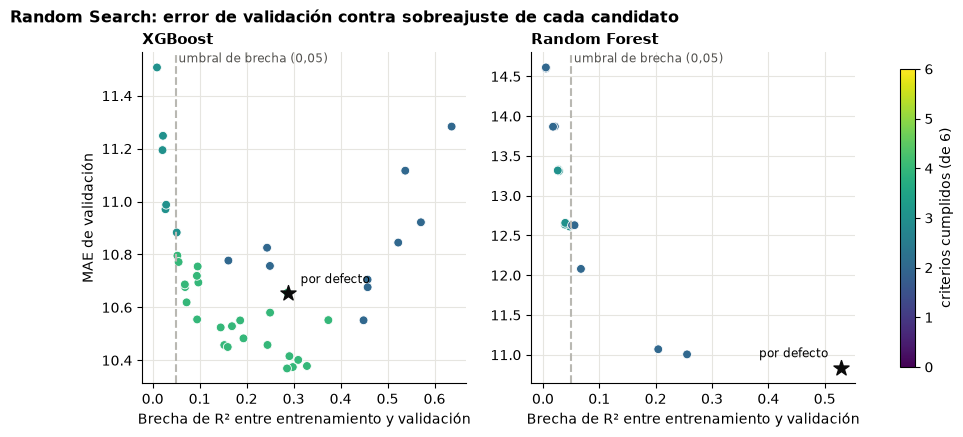

In [10]:
# ---------- Error contra sobreajuste: cada punto es un candidato del Random Search (la estrella es el valor por defecto)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for ax, t in zip(axes, ['xgb', 'rf']):
    r = RANDOM[t]
    p = ax.scatter(r['brecha_R2'], r['MAE'], c=r['criterios'], cmap='viridis', vmin=0, vmax=6, s=40, edgecolor='white', linewidth=0.6)
    ax.scatter([DEFECTO[t]['brecha_R2']], [DEFECTO[t]['MAE']], marker='*', s=130, color='#0b0b0b', zorder=5)
    ax.annotate('por defecto', (DEFECTO[t]['brecha_R2'], DEFECTO[t]['MAE']), xytext=((-9, 8) if t == 'rf' else (9, 7)), textcoords='offset points', ha=('right' if t == 'rf' else 'left'), fontsize=8.5)
    ax.axvline(UMBRALES['brecha_R2'], color='#b9b8b2', linestyle='--')
    ax.text(UMBRALES['brecha_R2'] + 0.005, ax.get_ylim()[1], 'umbral de brecha (0,05)', fontsize=8.5, va='top', color='#52514e')
    ax.set_title(NOMBRES[t], loc='left', fontsize=11, fontweight='bold')
    ax.set_xlabel('Brecha de R² entre entrenamiento y validación'); ax.set_ylabel('MAE de validación' if t == 'xgb' else '')
    ax.grid(color='#e6e5e0', linewidth=0.8); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.colorbar(p, ax=axes, label='criterios cumplidos (de 6)', shrink=0.9)
fig.suptitle('Random Search: error de validación contra sobreajuste de cada candidato', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '5_1_random_error_contra_sobreajuste.png', dpi=110, bbox_inches='tight'); plt.show()

## 5.3 Lectura del Random Search (y respuesta a H3)

**Ridge.** Los 20 candidatos dan el mismo MAE, 11,469; los cinco mejores son idénticos hasta el tercer decimal. Ridge tiene un solo hiperparámetro y una brecha de R² de 0,000: no sobreajusta, su error viene de ser un modelo demasiado simple para esta relación, y eso `alpha` no lo arregla.

**XGBoost.** De 40 candidatos, el MAE va de 10,369 a 11,507 (por defecto: 10,655). Ninguno cumple 5 criterios; el máximo es 4. El mejor según la regla tiene MAE 10,369, R² 0,421, RMSE 15,255, brecha 0,286, error en éxitos 29,199 y equidad 3,557: cumple R², RMSE, MAE y equidad, y le fallan la brecha y los éxitos. Es un modelo de profundidad 9, con 810 árboles, tasa de aprendizaje de 0,019 y `min_child_weight` de 36. Entre los cinco mejores se repite un patrón: `colsample_bytree` alto (entre 0,71 y 0,90) y tasa de aprendizaje baja (entre 0,019 y 0,029), o sea, muchos árboles que aprenden de a poco. Respecto del valor por defecto, el MAE bajó 0,286, unas 3,4 veces el ruido entre folds (0,085).

**Random Forest.** De 16 candidatos, el MAE va de 11,005 a 14,612, y ninguno supera al Random Forest por defecto (10,828). La regla elige un bosque podado (profundidad 22) que cumple la brecha (0,047) pero tiene MAE 12,613.

**Respuesta a H3: se cumple.** Cumplir la brecha cuesta MAE, y cuánto depende del modelo. En Random Forest, 11 de los 16 candidatos cumplen la brecha y el mejor de ellos tiene MAE 12,613, que es **1,785 más** que el mejor sin esa restricción (10,828); además la correlación entre brecha y MAE es de −0,86: cuanto menos sobreajusta un bosque, más se equivoca. En XGBoost, 5 de los 40 candidatos cumplen la brecha y el mejor de ellos tiene MAE 10,971, **0,602 más** que el mejor general (10,369). Esto tiene sentido: los árboles aprenden memorizando parte del entrenamiento, y limitarlos para que no lo hagan también limita lo que pueden predecir.

## 5.4 Fase 2: Grid Search acotado

**Hipótesis H4 (pregunta, antes de buscar).** Cuando el Random Search ya encontró la zona buena, ¿el Grid acotado agrega una mejora que valga lo que cuesta? Esperamos que afine algo, pero menos de lo que aportó el Random: la zona ya estaba encontrada y el Grid solo mueve cada valor un poco. Se responde en 5.5.

**Cómo se arma la malla.** No se escribe a mano para no ajustarla a los resultados que se ven: se arma sola alrededor del mejor candidato del Random. Cada hiperparámetro continuo toma tres valores (el del candidato y sus vecinos, multiplicando y dividiendo por un factor); la profundidad toma el valor y sus dos vecinos enteros; el número de árboles toma el 70%, el 100% y el 140%; `alpha` toma cinco valores en escala logarítmica. Lo que el Random Search dejó fijo en su mejor candidato queda fijo también aquí. Así el Grid explora solo la vecindad de lo que ya funcionó, que es su papel: afinar, no explorar.

In [11]:
# ---------- Fase 2: Grid Search acotado alrededor del mejor candidato del Random Search (la malla se arma sola desde ese candidato)
def alrededor(v, f):                          # un valor continuo: el valor y sus vecinos multiplicativos
    return [round(v / f, 4), round(v, 4), round(v * f, 4)]

def malla_alrededor(t, B):
    # B = hiperparámetros del mejor candidato del Random Search. Devuelve la malla del Grid: unos pocos libres y el resto fijo
    if t == 'ridge':
        libres = {'alpha': [float(a) for a in np.logspace(np.log10(B['alpha']) - 1, np.log10(B['alpha']) + 1, 5)]}
    elif t == 'xgb':
        libres = {'max_depth': [max(1, B['max_depth'] - 1), B['max_depth'], B['max_depth'] + 1],
                  'learning_rate': alrededor(B['learning_rate'], 1.5),
                  'n_estimators': [int(B['n_estimators'] * f) for f in (0.7, 1.0, 1.4)],
                  'min_child_weight': alrededor(B['min_child_weight'], 3)}
    elif t == 'rf':
        libres = {'min_samples_leaf': sorted({max(1, int(round(B['min_samples_leaf'] * f))) for f in (0.5, 1.0, 2.0)}),
                  'max_features': sorted({round(min(1.0, B['max_features'] * f), 4) for f in (0.75, 1.0, 1.25)})}
    return {**libres, **{k: [v] for k, v in B.items() if k not in libres}}

B = {t: mejor(RANDOM[t])['params'] for t in NOMBRES}
ESPACIO_GRID = {t: malla_alrededor(t, B[t]) for t in NOMBRES}
for t in NOMBRES:
    n = int(np.prod([len(v) for v in ESPACIO_GRID[t].values()]))
    libres = {k: [round(float(x), 4) if x is not None else None for x in v] for k, v in ESPACIO_GRID[t].items() if len(v) > 1}
    print(f'{NOMBRES[t]:14s} | {n:3d} combinaciones | {libres}')

Ridge          |   5 combinaciones | {'alpha': [0.0001, 0.0004, 0.0013, 0.0042, 0.0133]}
Random Forest  |   9 combinaciones | {'min_samples_leaf': [6.0, 13.0, 26.0], 'max_features': [0.6491, 0.8655, 1.0]}
XGBoost        |  81 combinaciones | {'max_depth': [8.0, 9.0, 10.0], 'learning_rate': [0.0125, 0.0187, 0.0281], 'n_estimators': [567.0, 810.0, 1134.0], 'min_child_weight': [12.1038, 36.3113, 108.934]}


**Nota.** En XGBoost se afinan los cuatro hiperparámetros que más mueven el compromiso entre ajuste y sobreajuste (profundidad, tasa de aprendizaje, número de árboles y peso mínimo de hoja), con 3 valores cada uno: 81 combinaciones. En Random Forest se afinan la poda (`min_samples_leaf`) y la fracción de variables por corte, alrededor del candidato elegido. En Ridge, los 5 valores de `alpha` cubren dos órdenes de magnitud alrededor del mejor. Una malla alrededor del mejor valor puede salirse del rango original del Random, y eso es justamente lo que se quiere ver.

In [12]:
GRID = {}
for t in ['ridge', 'xgb', 'rf']:
    busq = GridSearchCV(armar(t), ESPACIO_GRID[t], n_jobs=(4 if t == 'ridge' else 1), **PARAMS_COMUNES)
    GRID[t] = buscar(f'{t}_grid', busq, XTR[t])
    m, r = mejor(GRID[t]), mejor(RANDOM[t])
    print(f"{NOMBRES[t]:14s} | {len(GRID[t]):3d} combinaciones | búsqueda {GRID[t]['segundos_total'].iloc[0]:.0f} s | "
          f"mejor del Grid: MAE {m['MAE']:.3f}, {int(m['criterios'])} criterios (el Random: MAE {r['MAE']:.3f}, {int(r['criterios'])} criterios)")

Ridge          |   5 combinaciones | búsqueda 8 s | mejor del Grid: MAE 11.469, 3 criterios (el Random: MAE 11.469, 3 criterios)
XGBoost        |  81 combinaciones | búsqueda 3697 s | mejor del Grid: MAE 10.346, 4 criterios (el Random: MAE 10.369, 4 criterios)
Random Forest  |   9 combinaciones | búsqueda 609 s | mejor del Grid: MAE 12.613, 3 criterios (el Random: MAE 12.613, 3 criterios)


In [13]:
# ---------- Resumen del Grid y, en Random Forest, el efecto de cada valor de la poda
filas = []
for t in NOMBRES:
    res = GRID[t]
    filas.append({'modelo': NOMBRES[t], 'combinaciones': len(res), 'con 5 o más criterios': int((res['criterios'] >= 5).sum()),
                  'máximo de criterios': int(res['criterios'].max()), 'menor MAE': res['MAE'].min(), 'menor brecha_R2': res['brecha_R2'].min()})
display(pd.DataFrame(filas).set_index('modelo'))
display(GRID['rf'][['param_min_samples_leaf', 'param_max_features'] + COLS].sort_values(['param_min_samples_leaf', 'param_max_features']).reset_index(drop=True))

,combinaciones,con 5 o más criterios,máximo de criterios,menor MAE,menor brecha_R2
modelo,,,,,
Ridge,5,0,3,11.469,0.000
Random Forest,9,0,3,12.591,0.031
XGBoost,81,0,4,10.346,0.104


,param_min_samples_leaf,param_max_features,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios
0,6,0.649,12.601,0.046,16.691,0.307,0.066,34.144,4.848,2
1,6,0.866,12.591,0.049,16.718,0.305,0.068,34.098,4.841,2
2,6,1.000,12.591,0.054,16.734,0.303,0.068,34.088,4.852,2
3,13,0.649,12.631,0.042,16.722,0.304,0.046,34.287,4.876,3
4,13,0.866,12.613,0.043,16.742,0.303,0.047,34.260,4.923,3
5,13,1.000,12.613,0.048,16.757,0.301,0.048,34.244,4.931,3
6,26,0.649,12.670,0.045,16.762,0.301,0.031,34.452,4.968,3
7,26,0.866,12.651,0.046,16.781,0.299,0.032,34.405,5.011,2
8,26,1.000,12.651,0.048,16.796,0.298,0.032,34.407,5.022,2


## 5.5 Lectura del Grid Search (y respuesta a H4)

**Ridge.** Las 5 combinaciones dan el mismo MAE, 11,469. Ni con Random ni con Grid `alpha` cambia nada.

**XGBoost.** El mejor del Grid (MAE 10,346) mejora al del Random (10,369) en 0,023, que es **0,3 veces el ruido** entre folds (0,073): afinar alrededor del mejor punto no aporta nada medible. Peor aún, la brecha de R² sube de 0,286 a 0,401, porque la malla se centró en árboles de profundidad 8 a 10 y ninguna de sus 81 combinaciones cumple la brecha (la menor es 0,104). Y salió caro: el Grid tardó 62 minutos contra 15 del Random, porque las 81 combinaciones son modelos grandes (hasta 1.134 árboles de profundidad 10).

**Random Forest.** El mejor punto del Grid es el mismo del Random, porque es el centro de la malla, y ninguna de las 9 combinaciones cumple más de 3 criterios. El detalle de la tabla muestra el mecanismo: con hojas de 6 canciones la brecha queda sobre el límite (0,066 a 0,068); con 13 cumple (0,046 a 0,048); con 26 baja a 0,031, pero la equidad pasa de 5 en dos de las tres combinaciones (5,011 y 5,022) y se pierde otro criterio. El MAE casi no se mueve (12,59 a 12,67) y el R² queda cerca de 0,30. En este modelo, la poda cumple la brecha destruyendo la capacidad de predecir.

**Respuesta a H4: se cumple.** El Grid afina menos de lo que aportó el Random: en XGBoost la diferencia (−0,023) queda dentro del ruido, y en Random Forest y Ridge es cero. Con esta malla, el Grid fue la fase más cara y la que menos aportó.

## 5.6 Todas las fases juntas (y respuesta a H1)

Cada **candidato** es una combinación de hiperparámetros: en la fase 0 hay uno solo (el de fábrica) y en las demás, tantos como se probaron. La fila de cada fase muestra los resultados del **mejor** candidato de esa fase según la regla de la sección 1.2, no un promedio. El **ruido** es la desviación estándar del MAE entre los 5 folds: una diferencia de MAE menor que el ruido no se considera real. Se muestra el MAE como métrica principal, junto al RMSE, el R² y los criterios cumplidos.

In [14]:
def veredicto(dif, ruido):
    return 'mejora' if dif < -ruido else 'empeora' if dif > ruido else 'sin efecto'

filas = []
for t in NOMBRES:
    base = DEFECTO[t]
    for fase, res in [('0 defecto', None), ('1 random', RANDOM[t]), ('2 grid', GRID[t])]:
        r = base if res is None else mejor(res)
        filas.append({'modelo': NOMBRES[t], 'fase': fase, 'candidatos': 1 if res is None else len(res), 'MAE': r['MAE'], 'ruido': r['ruido'], 'RMSE': r['RMSE'],
                      'R2': r['R2'], 'brecha_R2': r['brecha_R2'], 'MAE_exitos': r['MAE_exitos'], 'brecha_cuartiles': r['brecha_cuartiles'],
                      'criterios': int(r['criterios']), 'cambio MAE vs defecto': r['MAE'] - base['MAE'],
                      'veredicto': veredicto(r['MAE'] - base['MAE'], base['ruido']),
                      'menor MAE de la fase': base['MAE'] if res is None else res['MAE'].min(),
                      'segundos': r['segundos_total'] if res is None else res['segundos_total'].iloc[0]})
FASES = pd.DataFrame(filas).set_index(['modelo', 'fase'])
display(FASES)

candidatos    MAE  ruido   RMSE    R2  brecha_R2  MAE_exitos  brecha_cuartiles  criterios  cambio MAE vs defecto   veredicto  \
modelo        fase                                                                                                                                      
Ridge         0 defecto           1 11.469  0.046 16.130 0.353      0.000      32.769             4.142          3                  0.000  sin efecto   
              1 random           20 11.469  0.046 16.130 0.353      0.000      32.769             4.142          3                 -0.000  sin efecto   
              2 grid              5 11.469  0.046 16.130 0.353      0.000      32.769             4.142          3                 -0.000  sin efecto   
Random Forest 0 defecto           1 10.828  0.079 15.622 0.393      0.528      30.014             3.613          2                  0.000  sin efecto   
              1 random           16 12.613  0.043 16.742 0.303      0.047      34.260             4.923          3                  1.784     empeora   
              2 grid              9 12.613  0.043 16.742 0.303      0.047      34.260             4.923          3                  1.784     empeora   
XGBoost       0 defecto           1 10.655  0.085 15.663 0.390      0.288      29.002             3.752          2                  0.000  sin efecto   
              1 random           40 10.369  0.074 15.255 0.421      0.286      29.199             3.557          4                 -0.286      mejora   
              2 grid             81 10.346  0.073 15.303 0.417      0.401      28.726             3.490          4                 -0.309      mejora   

                         menor MAE de la fase  segundos  
modelo        fase                                       
Ridge         0 defecto                11.469     2.758  
              1 random                 11.469     4.765  
              2 grid                   11.469     8.367  
Random Forest 0 defecto                10.828   166.726  
              1 random                 11.005   586.540  
              2 grid                   12.591   609.390  
XGBoost       0 defecto                10.655     3.419  
              1 random                 10.369   888.325  
              2 grid                   10.346 3,696.719

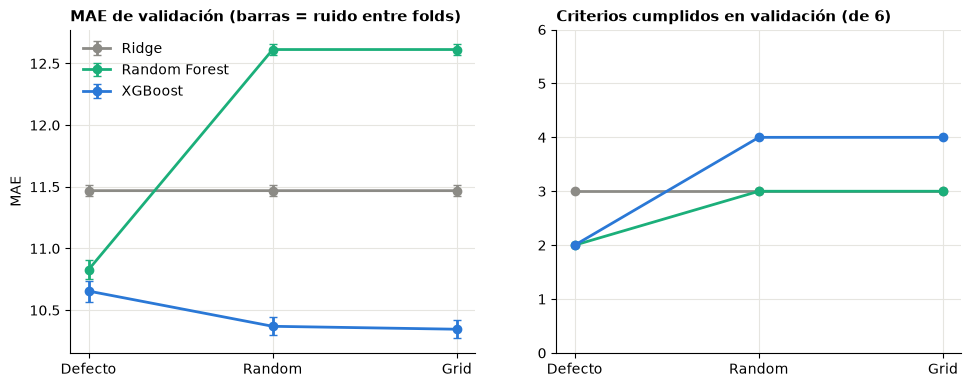

In [15]:
# ---------- Figura: MAE de validación (con el ruido entre folds) y criterios cumplidos en cada fase
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
colores = {'Ridge': '#8c8b86', 'Random Forest': '#1baf7a', 'XGBoost': '#2a78d6'}
fases = ['0 defecto', '1 random', '2 grid']
for modelo, c in colores.items():
    g = FASES.loc[modelo].loc[fases]
    axes[0].errorbar(range(3), g['MAE'], yerr=g['ruido'], marker='o', color=c, capsize=3, linewidth=2, label=modelo)
    axes[1].plot(range(3), g['criterios'], marker='o', color=c, linewidth=2, label=modelo)
axes[0].set_title('MAE de validación (barras = ruido entre folds)', loc='left', fontsize=10.5, fontweight='bold'); axes[0].set_ylabel('MAE')
axes[1].set_title('Criterios cumplidos en validación (de 6)', loc='left', fontsize=10.5, fontweight='bold'); axes[1].set_yticks(range(0, 7))
for ax in axes:
    ax.set_xticks(range(3)); ax.set_xticklabels(['Defecto', 'Random', 'Grid']); ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
axes[0].legend(frameon=False)
fig.savefig(IMAGENES / '5_2_fases_de_optimizacion.png', dpi=110, bbox_inches='tight'); plt.show()

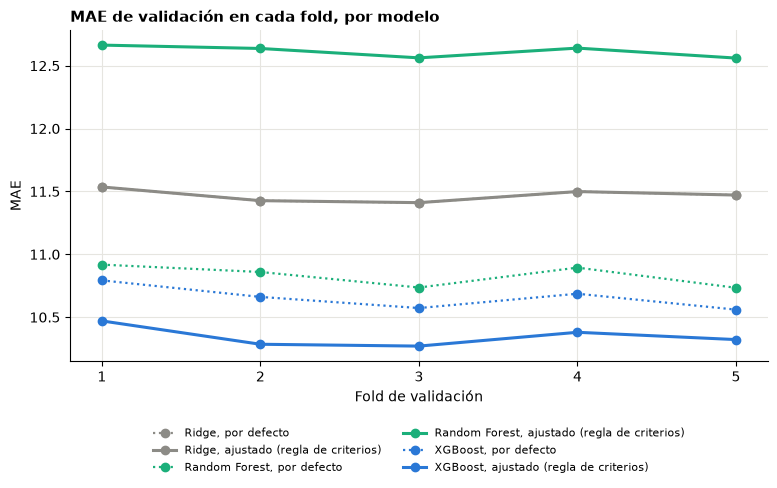

In [16]:
# ---------- Figura: estabilidad por fold. MAE de validación en cada uno de los 5 folds, con parámetros por defecto (punteado) y con el mejor candidato de la búsqueda (sólido)
fig, ax = plt.subplots(figsize=(9, 4.3))
for modelo, t, c in [('Ridge', 'ridge', '#8c8b86'), ('Random Forest', 'rf', '#1baf7a'), ('XGBoost', 'xgb', '#2a78d6')]:
    elegido = mejor(GRID[t])
    por_defecto = [DEFECTO[t][f'split{k}_test_MAE'] for k in range(5)]
    ajustado = [elegido[f'split{k}_test_MAE'] for k in range(5)]
    ax.plot(range(1, 6), por_defecto, marker='o', color=c, linestyle=':', linewidth=1.6, label=f'{modelo}, por defecto')
    ax.plot(range(1, 6), ajustado, marker='o', color=c, linewidth=2.2, label=f'{modelo}, ajustado (regla de criterios)')
ax.set_xticks(range(1, 6)); ax.set_xlabel('Fold de validación'); ax.set_ylabel('MAE')
ax.set_title('MAE de validación en cada fold, por modelo', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.17)); ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '5_4_estabilidad_por_fold.png', dpi=110, bbox_inches='tight'); plt.show()

**Qué pasó con cada modelo.**

- **Ridge:** las tres fases dan 11,469. Ajustar no cambia nada que se distinga del ruido (0,046).
- **Random Forest:** el candidato que elige la regla empeora el MAE de 10,828 a 12,613 (+1,784, unas 41 veces el ruido de 0,043) a cambio de bajar la brecha de R² de 0,528 a 0,047. Ni siquiera el menor MAE de las búsquedas (11,005 en el Random y 12,591 en el Grid) supera a los hiperparámetros por defecto: el mejor Random Forest que encontramos es el que ya venía de fábrica.
- **XGBoost:** el MAE baja de 10,655 a 10,369 con el Random y a 10,346 con el Grid (−0,309 en total, unas 3,6 veces el ruido de 0,085), y sube de 2 a 4 los criterios cumplidos: el R² (de 0,390 a 0,417) y el RMSE (de 15,663 a 15,303) pasan sus umbrales. Lo que empeora es la brecha de R², de 0,288 a 0,401.

**Estabilidad por fold.** El XGBoost ajustado queda por debajo del XGBoost por defecto en los 5 folds (por ejemplo, 10,47 contra 10,79 en el primero y 10,32 contra 10,56 en el último), así que su mejora no depende de una partición favorable. El Random Forest podado queda por encima del por defecto en los 5 folds, y Ridge ajustado coincide con Ridge por defecto en todos. Las líneas de cada modelo suben y bajan juntas: el MAE depende de lo difícil que sea cada fold más que del modelo.

**Respuesta a H1: se cumple solo en XGBoost.** Ajustar los hiperparámetros mejoró el error de validación más que el ruido en XGBoost, no cambió nada en Ridge, y en Random Forest empeoró el resultado (cuando se busca cumplir criterios) o lo dejó igual (cuando se busca el menor MAE). Es lo más importante que dejó la búsqueda: **para dos de los tres modelos, los hiperparámetros por defecto ya eran buenos**.

**Respuesta a H2: no se cumple.** Ningún candidato de ningún modelo cumple 5 o más criterios en validación; el máximo es 4, con XGBoost. A los de XGBoost les faltan siempre la brecha de R² y el error en éxitos.

## 5.7 Aporte de los ensambles: un árbol solo contra bosque y boosting

Random Forest (bagging) y XGBoost (boosting) son ensambles de árboles. Para mostrar que combinar árboles aporta algo, los comparamos con **un árbol de decisión solo**, ajustado con el mismo cuidado (Grid Search sobre profundidad y tamaño de hoja, mismos 5 folds, misma tabla que Random Forest). No busca elegir entre modelos: busca mostrar el aporte del ensamble.

In [17]:
# ---------- Referencia: un árbol de decisión solo, con su propia búsqueda (misma tabla y mismos folds que Random Forest)
from sklearn.tree import DecisionTreeRegressor
espacio_arbol = {'max_depth': [3, 5, 8, 12, None], 'min_samples_leaf': [1, 10, 40]}
ARBOL = buscar('arbol_grid', GridSearchCV(DecisionTreeRegressor(random_state=SEMILLA), espacio_arbol, n_jobs=4, **PARAMS_COMUNES), XTR['rf'])

def piscina(t):
    return pd.concat([pd.DataFrame([DEFECTO[t]]).infer_objects(), RANDOM[t], GRID[t]], ignore_index=True)

filas = [('Árbol de decisión solo (menor MAE de 15 combinaciones)', ARBOL.sort_values('MAE').iloc[0]),
         ('Random Forest, parámetros por defecto', DEFECTO['rf']),
         ('XGBoost, parámetros por defecto', DEFECTO['xgb']),
         ('Random Forest (menor MAE de sus búsquedas)', piscina('rf').sort_values('MAE').iloc[0]),
         ('XGBoost (menor MAE de sus búsquedas)', piscina('xgb').sort_values('MAE').iloc[0])]
ENSAMBLES = pd.DataFrame([{'modelo': n, 'MAE': r['MAE'], 'ruido (desv. entre folds)': r['ruido'], 'RMSE': r['RMSE'], 'R2': r['R2'], 'brecha_R2': r['brecha_R2']} for n, r in filas]).set_index('modelo')
ENSAMBLES['MAE menos que el árbol solo (%)'] = (1 - ENSAMBLES['MAE'] / ENSAMBLES.iloc[0]['MAE']) * 100
display(ENSAMBLES)
print('Árbol solo, mejor combinación:', ARBOL.sort_values('MAE').iloc[0]['params'])

,MAE,ruido (desv. entre folds),RMSE,R2,brecha_R2,MAE menos que el árbol solo (%)
modelo,,,,,,
Árbol de decisión solo (menor MAE de 15 combinaciones),11.906,0.079,16.814,0.296,0.153,0.000
"Random Forest, parámetros por defecto",10.828,0.079,15.622,0.393,0.528,9.049
"XGBoost, parámetros por defecto",10.655,0.085,15.663,0.390,0.288,10.507
Random Forest (menor MAE de sus búsquedas),10.828,0.079,15.622,0.393,0.528,9.049
XGBoost (menor MAE de sus búsquedas),10.346,0.073,15.303,0.417,0.401,13.105


Árbol solo, mejor combinación: {'max_depth': None, 'min_samples_leaf': 40}


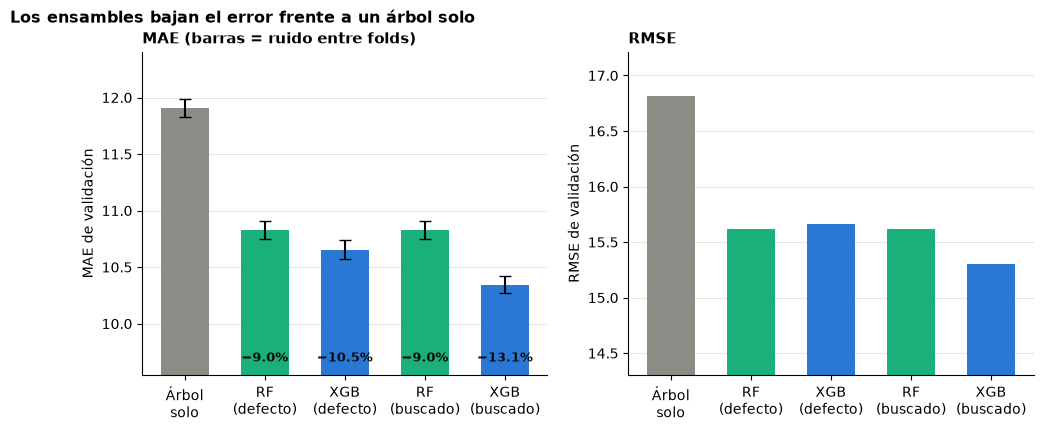

In [18]:
# ---------- Figura: un árbol solo contra bosque y boosting (MAE con el ruido entre folds, y RMSE)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
etiquetas = ['Árbol\nsolo', 'RF\n(defecto)', 'XGB\n(defecto)', 'RF\n(buscado)', 'XGB\n(buscado)']   # RF = Random Forest, XGB = XGBoost
colores_b = ['#8c8b86', '#1baf7a', '#2a78d6', '#1baf7a', '#2a78d6']
barras = axes[0].bar(etiquetas, ENSAMBLES['MAE'], yerr=ENSAMBLES['ruido (desv. entre folds)'], color=colores_b, capsize=4, width=0.6)
piso = ENSAMBLES['MAE'].min() - 0.8
for b_, pct in zip(barras, ENSAMBLES['MAE menos que el árbol solo (%)']):
    if pct > 0:
        axes[0].text(b_.get_x() + b_.get_width() / 2, piso + 0.12, f'−{pct:.1f}%', ha='center', color='#0b0b0b', fontsize=9.5, fontweight='bold')
axes[0].set_ylim(piso, ENSAMBLES['MAE'].max() + 0.5); axes[0].set_ylabel('MAE de validación')
axes[0].set_title('MAE (barras = ruido entre folds)', loc='left', fontsize=10.5, fontweight='bold')
axes[1].bar(etiquetas, ENSAMBLES['RMSE'], color=colores_b, width=0.6)
axes[1].set_ylim(ENSAMBLES['RMSE'].min() - 1.0, ENSAMBLES['RMSE'].max() + 0.4); axes[1].set_ylabel('RMSE de validación')
axes[1].set_title('RMSE', loc='left', fontsize=10.5, fontweight='bold')
for ax in axes:
    ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.suptitle('Los ensambles bajan el error frente a un árbol solo', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '5_3_ensambles.png', dpi=110, bbox_inches='tight'); plt.show()

El árbol solo llega a un MAE de 11,906 (R² 0,296). Los dos ensambles lo bajan: el bosque (bagging) a 10,828, un 9,0% menos, y XGBoost (boosting) a 10,655 por defecto (10,5% menos) y a 10,346 tras buscar (13,1% menos). El RMSE va en la misma dirección: de 16,814 en el árbol solo a 15,622 en el bosque y a 15,303 en XGBoost buscado. Cada ensamble reduce algo distinto: promediar árboles distintos compensa sus errores y reduce la varianza (bagging), y que cada árbol corrija lo que faltaba en los anteriores reduce el sesgo (boosting). Lo que más baja el error es el boosting con hiperparámetros buscados; el Random Forest buscado no mejora al de fábrica, por eso sus dos barras son iguales.

Esta comparación no busca elegir entre modelos, sino mostrar que combinar árboles reduce el error frente a un árbol solo.

---
# 6. Evaluación en prueba de los finalistas

## 6.1 Quiénes son los finalistas

Hasta aquí no se ha usado la prueba. De todos los candidatos probados (defecto, Random y Grid) pasan a la prueba, por modelo, dos: el que cumple **más criterios** (la regla de la sección 1.2) y el de **menor MAE** de validación. Si son el mismo candidato, se evalúa uno. Es la única vez que se mira la prueba.

**Hipótesis H5 (pregunta, antes de mirar la prueba).** El candidato ganador se eligió como el mejor entre decenas de combinaciones, comparadas con las mismas canciones de validación. ¿Sus resultados se mantienen en la prueba, o están algo inflados por haberlo elegido entre tantos? Esperamos que en la prueba salgan algo peores y que los criterios cumplidos por poco no se mantengan. Se responde en 6.3.

In [19]:
# ---------- Finalistas: todos los candidatos de cada modelo juntos
POOL = {}
for t in NOMBRES:
    d = pd.DataFrame([DEFECTO[t]]).infer_objects().assign(fase='0 defecto')
    POOL[t] = pd.concat([d, RANDOM[t].assign(fase='1 random'), GRID[t].assign(fase='2 grid')], ignore_index=True)

FINALISTAS = {}
for t in NOMBRES:
    a, b = mejor(POOL[t]), POOL[t].sort_values('MAE').iloc[0]
    FINALISTAS[(t, 'más criterios')] = a
    if a['params_json'] != b['params_json']:
        FINALISTAS[(t, 'menor MAE')] = b
filas = [{'finalista': f'{NOMBRES[t]} ({tipo})', 'fase': r['fase'], 'MAE valid.': r['MAE'], 'ruido': r['ruido'], 'criterios en validación': int(r['criterios']), 'hiperparámetros': r['params']}
         for (t, tipo), r in FINALISTAS.items()]
pd.DataFrame(filas).set_index('finalista')

,fase,MAE valid.,ruido,criterios en validación,hiperparámetros
finalista,,,,,
Ridge (más criterios),2 grid,11.469,0.046,3,{'alpha': 0.00013289448722869187}
Random Forest (más criterios),1 random,12.613,0.043,3,"{'max_depth': 22, 'max_features': 0.8655000144869414, 'max_samples': 0.865996970905702..."
Random Forest (menor MAE),0 defecto,10.828,0.079,2,{}
XGBoost (más criterios),2 grid,10.346,0.073,4,"{'colsample_bytree': 0.8411296715444633, 'learning_rate': 0.0125, 'max_depth': 10, 'mi..."


**Nota.** Son cuatro finalistas. En Ridge, el que cumple más criterios tiene `alpha` ≈ 0,0001, prácticamente el valor de fábrica. En Random Forest hay dos: el bosque podado de la regla y **el de menor MAE, que es el Random Forest por defecto** (ninguna de las 25 combinaciones buscadas lo mejoró). En XGBoost el que cumple más criterios y el de menor MAE son el mismo candidato, el mejor del Grid (profundidad 10, tasa de aprendizaje de 0,0125 y 1.134 árboles).

## 6.2 Prueba: los seis criterios

Cada finalista se vuelve a entrenar con **todo** el entrenamiento y se mide una vez en la prueba. El criterio 4 (brecha de R²) compara el R² en entrenamiento con el de prueba, como en la EV2. Para poder comparar con justicia, los tres modelos con hiperparámetros **por defecto** se entrenan y se miden de la misma forma: son el punto de comparación de toda la sección 8.

In [20]:
# ---------- Medir unas predicciones en la prueba con los seis criterios (se usa en todo lo que sigue)
def fila_prueba(nombre, p_tr, p_te):
    m = medidas(p_te, GENERO_TE, y_test)
    m['brecha_R2'] = r2_score(y_train, p_tr) - m['R2']
    c = [m['R2'] >= UMBRALES['R2'], m['RMSE'] <= UMBRALES['RMSE'], m['MAE'] <= UMBRALES['MAE'], m['brecha_R2'] <= UMBRALES['brecha_R2'],
         m['MAE_exitos'] <= UMBRALES['MAE_exitos'], m['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']]
    return {'candidato': nombre, 'R2': m['R2'], 'RMSE': m['RMSE'], 'MAE': m['MAE'], 'brecha_R2': m['brecha_R2'], 'MAE_exitos': m['MAE_exitos'],
            'brecha_cuartiles': m['brecha_cuartiles'], 'criterios': sum(c), 'no cumple': [n for n, ok in zip(range(1, 7), c) if not ok]}

UMBRAL_TXT = pd.DataFrame([{'R2': '>= 0,40', 'RMSE': f"<= {UMBRALES['RMSE']:.2f}", 'MAE': f"<= {UMBRALES['MAE']:.2f}", 'brecha_R2': '<= 0,05', 'MAE_exitos': '<= 20', 'brecha_cuartiles': '<= 5'}], index=['UMBRAL'])

# ---------- Los tres modelos por defecto (punto de comparación) y los finalistas, cada uno entrenado con todo el entrenamiento
AJUSTADOS, filas_def, filas = {}, [], []
for t in NOMBRES:
    m = armar(t).fit(XTR[t], y_train)
    AJUSTADOS[(t, 'defecto')] = m
    filas_def.append(fila_prueba(f'{NOMBRES[t]} (por defecto)', m.predict(XTR[t]), m.predict(XTE[t])))
for (t, tipo), r in FINALISTAS.items():
    t0 = time.time()
    m = armar(t, **r['params']).fit(XTR[t], y_train)
    seg = time.time() - t0
    AJUSTADOS[(t, tipo)] = m
    filas.append({**fila_prueba(f'{NOMBRES[t]} ({tipo})', m.predict(XTR[t]), m.predict(XTE[t])), 'segundos': seg})
PRUEBA_DEFECTO = pd.DataFrame(filas_def).set_index('candidato')
PRUEBA = pd.DataFrame(filas).set_index('candidato')
display(UMBRAL_TXT)
print('Hiperparámetros por defecto, en la prueba:')
display(PRUEBA_DEFECTO)
print('Finalistas (hiperparámetros buscados), en la prueba:')
display(PRUEBA)

C:\Users\usuario\Desktop\SpotifyTracks\.venv\Lib\site-packages\xgboost\core.py:569: UserWarning: [04:40:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
UMBRAL,">= 0,40",<= 15.51,<= 13.46,"<= 0,05",<= 20,<= 5


Hiperparámetros por defecto, en la prueba:


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
candidato,,,,,,,,
Ridge (por defecto),0.348,16.267,11.516,0.005,32.821,4.408,3,"[1, 2, 5]"
Random Forest (por defecto),0.388,15.756,10.846,0.533,29.950,3.940,2,"[1, 2, 4, 5]"
XGBoost (por defecto),0.386,15.788,10.643,0.265,29.360,3.984,2,"[1, 2, 4, 5]"


Finalistas (hiperparámetros buscados), en la prueba:


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple,segundos
candidato,,,,,,,,,
Ridge (más criterios),0.348,16.267,11.516,0.005,32.821,4.408,3,"[1, 2, 5]",0.008
Random Forest (más criterios),0.296,16.896,12.735,0.045,34.515,5.458,2,"[1, 2, 5, 6]",13.725
Random Forest (menor MAE),0.388,15.756,10.846,0.533,29.950,3.940,2,"[1, 2, 4, 5]",40.142
XGBoost (más criterios),0.410,15.468,10.438,0.388,29.036,3.751,4,"[4, 5]",17.859


**Nota.** `fila_prueba` mide cualquier conjunto de predicciones con los seis criterios, para que todos los candidatos, los de esta sección y los de la 7, sean comparables entre sí. Los hiperparámetros por defecto se miden aquí con las tablas de la EV2 y el mismo procedimiento; si esta tabla coincide con la de la EV2, el traspaso de datos está bien.

In [21]:
# ---------- Comprobación: ¿los modelos por defecto dan en la prueba lo mismo que midió la EV2?
filas = []
for t in NOMBRES:
    e, a = met_ev2['modelos'][t], PRUEBA_DEFECTO.loc[f'{NOMBRES[t]} (por defecto)']
    filas.append({'modelo': NOMBRES[t], 'MAE EV2': e['MAE test'], 'MAE aquí': a['MAE'], 'R2 EV2': e['R2 test'], 'R2 aquí': a['R2'],
                  'brecha R2 EV2': e['R2 train'] - e['R2 test'], 'brecha R2 aquí': a['brecha_R2']})
display(pd.DataFrame(filas).set_index('modelo'))

,MAE EV2,MAE aquí,R2 EV2,R2 aquí,brecha R2 EV2,brecha R2 aquí
modelo,,,,,,
Ridge,11.516,11.516,0.348,0.348,0.009,0.005
Random Forest,10.846,10.846,0.388,0.388,0.533,0.533
XGBoost,10.643,10.643,0.386,0.386,0.265,0.265


## 6.3 Lectura de la prueba (y respuesta a H5 y a H1)

**Qué muestra la prueba.**

- **Los hiperparámetros por defecto reproducen exactamente lo que midió la EV2** (MAE 11,516, 10,846 y 10,643 en la prueba), así que el traspaso de datos entre las dos etapas está bien.
- **XGBoost optimizado es el único que mejora.** Pasa de cumplir 2 criterios a cumplir 4: R² de 0,386 a 0,410 y RMSE de 15,788 a 15,468 cruzan sus umbrales, y el MAE baja de 10,643 a 10,438 (−0,205). Le fallan la brecha de R² (0,388, peor que el 0,265 que tenía por defecto) y el error en éxitos (29,036).
- **Ridge no cambia** (MAE 11,516 y 3 criterios).
- **Random Forest podado** (el de la regla) es el peor: R² 0,296 y MAE 12,735, y pasa de 3 criterios en validación a 2 en la prueba. **El de menor MAE es el que ya teníamos por defecto** (MAE 10,846 y 2 criterios).
- **Ningún finalista cumple los seis criterios.** El máximo es 4, y es XGBoost.

**Respuesta a H5: se cumple en lo esperado.** Las cifras del ganador empeoran un poco al pasar de validación a prueba: en XGBoost el MAE sube de 10,346 a 10,438 (+0,092), el RMSE de 15,303 a 15,468 (+0,165) y el R² baja de 0,417 a 0,410. Aun así, sus 4 criterios se mantienen, porque los cumplía con margen (el RMSE con 0,21 de holgura en validación, y todavía con 0,045 en la prueba). El Random Forest podado, en cambio, pierde un criterio: cumplía la equidad por apenas 0,077 (4,923 contra un límite de 5) y en la prueba da 5,458. O sea que los criterios que se cumplen por poco no sobreviven a canciones nuevas y los que tienen margen sí.

**Respuesta a H1 en la prueba.** Se confirma lo de validación: de los tres modelos, solo XGBoost mejoró al optimizar.

---
# 7. Experimentos: pérdida absoluta y artista

## 7.0 Qué se prueba y cómo

La búsqueda de la sección 5 dejó a los tres modelos con sus hiperparámetros ajustados. Pero hay dos preguntas que ningún Random ni Grid contesta, porque no son hiperparámetros: **qué error está minimizando el modelo** (la función de pérdida) y **qué información le damos para aprender**. Esta sección prueba dos ideas, cada una con su razón y con lo que esperamos antes de medir:

| Experimento | Por qué se prueba | Qué esperamos |
|---|---|---|
| **7.1 Pérdida absoluta** (H6) | La métrica principal es el MAE, y la pérdida cuadrática no lo optimiza directamente | Menos MAE, pero peor R² y RMSE |
| **7.2 Diagnóstico del artista** (H7) | En el EDA el artista explicaba más que el género y lo dejamos fuera | Una mejora grande que dependa de que el artista tenga historial |

Los dos se miden con la misma disciplina que la búsqueda: primero en validación cruzada, y a la prueba pasan una sola vez. Una diferencia de MAE menor que el ruido entre folds se considera "sin efecto".

In [22]:
# ---------- Referencia de los tres experimentos: el XGBoost de pérdida cuadrática que dejó la búsqueda
PARAMS_A = mejor(GRID['xgb'])['params']
base_ref = mejor(GRID['xgb'])
FILAS_PRUEBA = [fila_prueba('XGBoost A: pérdida cuadrática (referencia)', AJUSTADOS[('xgb', 'más criterios')].predict(XTR['xgb']),
                            AJUSTADOS[('xgb', 'más criterios')].predict(XTE['xgb']))]
print('Hiperparámetros del XGBoost de referencia (A):', PARAMS_A)
print('Validación:', {c: round(float(base_ref[c]), 3) for c in COLS})

Hiperparámetros del XGBoost de referencia (A): {'colsample_bytree': 0.8411296715444633, 'learning_rate': 0.0125, 'max_depth': 10, 'min_child_weight': 12.1038, 'n_estimators': 1134, 'reg_alpha': 0.008207295819490819, 'reg_lambda': 0.3348611630346182, 'subsample': 0.9910841716647179}
Validación: {'MAE': 10.346, 'ruido': 0.073, 'RMSE': 15.303, 'R2': 0.417, 'brecha_R2': 0.401, 'MAE_exitos': 28.726, 'brecha_cuartiles': 3.49, 'criterios': 4.0}


**Nota.** Esa referencia, a la que llamamos A, es el XGBoost que eligió la regla de la sección 1.2 con la pérdida cuadrática de fábrica. Su resultado en la prueba ya se midió en la sección 6; aquí solo se vuelve a anotar en la lista para comparar los experimentos.

## 7.1 Pérdida absoluta (H6)

**Por qué.** Hasta aquí XGBoost minimizó el error cuadrático (`reg:squarederror`): equivocarse por 20 puntos "cuesta" cuatro veces más que equivocarse por 10, y la mejor predicción para ese costo es la **media**. El MAE, en cambio, cuenta cada punto de error por igual, y la mejor predicción para ese costo es la **mediana**. En la popularidad hay muchas canciones con valor 0 y unos pocos éxitos de 80 o 90, así que media y mediana se separan bastante. La pérdida absoluta (`reg:absoluteerror`) optimiza justo lo que más nos importa medir, así que merece una comparación justa con la cuadrática.

**Hipótesis H6 (pregunta, antes de medir).** ¿Optimizar directamente el MAE, con la pérdida absoluta, logra menos error que la cuadrática, y qué se pierde a cambio? Esperamos menos MAE pero peor R² y RMSE, porque esas dos medidas se calculan con errores al cuadrado y castigan los errores grandes, que es justo lo que la pérdida absoluta deja de castigar. También esperamos más sobreajuste. Para que la comparación sea justa, la pérdida absoluta se busca con el **mismo procedimiento**: Random Search con el mismo espacio y las mismas 40 combinaciones, y un Grid acotado alrededor de su mejor resultado.

In [23]:
# ---------- XGBoost con pérdida absoluta: mismo Random Search (mismo espacio, misma semilla) y Grid Search acotado
OBJ_ABS = {'objective': 'reg:absoluteerror'}
busq = RandomizedSearchCV(armar('xgb', **OBJ_ABS), ESPACIO_RANDOM['xgb'], n_iter=N_ITER['xgb'], random_state=SEMILLA, n_jobs=1, **PARAMS_COMUNES)
RANDOM_ABS = buscar('xgb_abs_random', busq, XTR['xgb'])
B_ABS = mejor(RANDOM_ABS)['params']
GRID_ABS = buscar('xgb_abs_grid', GridSearchCV(armar('xgb', **OBJ_ABS), malla_alrededor('xgb', B_ABS), n_jobs=1, **PARAMS_COMUNES), XTR['xgb'])

POOL_ABS = pd.concat([RANDOM_ABS.assign(fase='1 random'), GRID_ABS.assign(fase='2 grid')], ignore_index=True)
POOL_CUAD = pd.concat([DEFECTO['xgb'].to_frame().T.infer_objects().assign(fase='0 defecto'), RANDOM['xgb'].assign(fase='1 random'), GRID['xgb'].assign(fase='2 grid')], ignore_index=True)
MEJOR_ABS_CRIT, MEJOR_ABS_MAE = mejor(POOL_ABS), POOL_ABS.sort_values('MAE').iloc[0]
PARAMS_B = MEJOR_ABS_MAE['params']          # B = el de menor MAE de la pérdida absoluta (es su razón de ser: ser el especialista en MAE)

filas = [{'candidato': 'A cuadrática: más criterios (regla)', **{c: mejor(POOL_CUAD)[c] for c in COLS}},
         {'candidato': 'A cuadrática: menor MAE', **{c: POOL_CUAD.sort_values('MAE').iloc[0][c] for c in COLS}},
         {'candidato': 'B absoluta: más criterios (regla)', **{c: MEJOR_ABS_CRIT[c] for c in COLS}},
         {'candidato': 'B absoluta: menor MAE', **{c: MEJOR_ABS_MAE[c] for c in COLS}}]
display(pd.DataFrame(filas).set_index('candidato'))
print('Tiempo de la búsqueda con pérdida absoluta (Random + Grid):', f"{RANDOM_ABS['segundos_total'].iloc[0] + GRID_ABS['segundos_total'].iloc[0]:.0f} s")
print('Hiperparámetros de B (menor MAE):', PARAMS_B)

,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios
candidato,,,,,,,,
A cuadrática: más criterios (regla),10.346,0.073,15.303,0.417,0.401,28.726,3.490,4
A cuadrática: menor MAE,10.346,0.073,15.303,0.417,0.401,28.726,3.490,4
B absoluta: más criterios (regla),10.002,0.077,15.859,0.374,0.048,30.349,4.134,3
B absoluta: menor MAE,9.831,0.088,15.551,0.398,0.160,29.280,4.026,2


Tiempo de la búsqueda con pérdida absoluta (Random + Grid): 1583 s
Hiperparámetros de B (menor MAE): {'colsample_bytree': 0.9011814973535428, 'learning_rate': 0.0261423416776307, 'max_depth': 8, 'min_child_weight': 17.268730522918634, 'n_estimators': 970, 'reg_alpha': 0.2309786149269357, 'reg_lambda': 10.781845035122265, 'subsample': 0.508293914463928}


**Nota.** La búsqueda con pérdida absoluta es una réplica de la de la sección 5: mismo espacio, mismas 40 combinaciones al azar y un Grid armado con la misma función `malla_alrededor`. Lo único que cambia es `objective`. De cada búsqueda se muestran los dos candidatos de siempre: el de la regla de criterios y el de menor MAE. Llamamos **B** al de menor MAE de la pérdida absoluta.

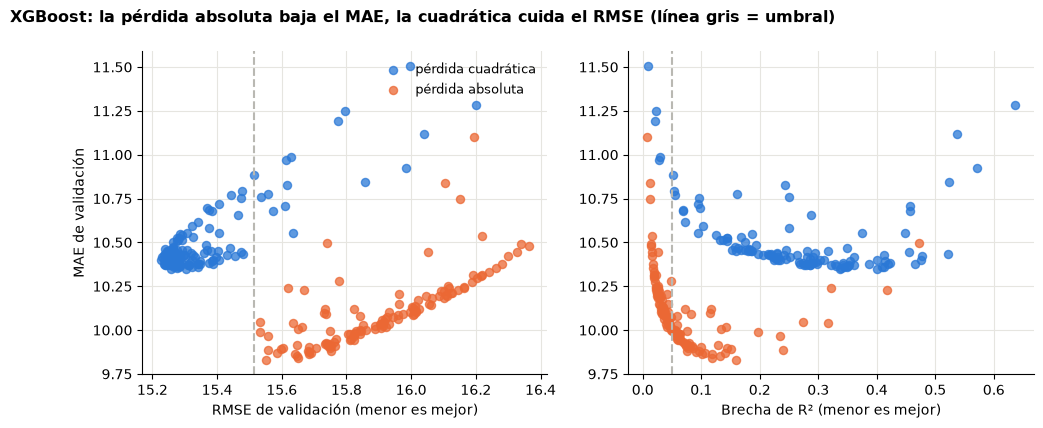

In [24]:
# ---------- Figura: cada candidato de XGBoost (todas las fases) según su RMSE y su MAE de validación, por función de pérdida
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
cuad, absol = POOL_CUAD.iloc[1:], POOL_ABS          # sin el punto por defecto
for ax, col, titulo in [(axes[0], 'RMSE', 'RMSE de validación (menor es mejor)'), (axes[1], 'brecha_R2', 'Brecha de R² (menor es mejor)')]:
    ax.scatter(cuad[col], cuad['MAE'], s=34, color='#2a78d6', alpha=0.75, label='pérdida cuadrática')
    ax.scatter(absol[col], absol['MAE'], s=34, color='#eb6834', alpha=0.75, label='pérdida absoluta')
    ax.set_xlabel(titulo); ax.set_ylabel('MAE de validación' if col == 'RMSE' else '')
    ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
axes[0].axvline(UMBRALES['RMSE'], color='#b9b8b2', linestyle='--'); axes[1].axvline(UMBRALES['brecha_R2'], color='#b9b8b2', linestyle='--')
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle('XGBoost: la pérdida absoluta baja el MAE, la cuadrática cuida el RMSE (línea gris = umbral)', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '7_1_perdida_cuadratica_contra_absoluta.png', dpi=110, bbox_inches='tight'); plt.show()

In [25]:
# ---------- B en la prueba (una sola vez)
mB = armar('xgb', **OBJ_ABS, **PARAMS_B).fit(XTR['xgb'], y_train)
FILAS_PRUEBA.append(fila_prueba('XGBoost B: pérdida absoluta', mB.predict(XTR['xgb']), mB.predict(XTE['xgb'])))
display(UMBRAL_TXT)
display(pd.DataFrame(FILAS_PRUEBA).set_index('candidato'))

,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
UMBRAL,">= 0,40",<= 15.51,<= 13.46,"<= 0,05",<= 20,<= 5


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
candidato,,,,,,,,
XGBoost A: pérdida cuadrática (referencia),0.410,15.468,10.438,0.388,29.036,3.751,4,"[4, 5]"
XGBoost B: pérdida absoluta,0.383,15.819,9.926,0.159,29.273,4.124,2,"[1, 2, 4, 5]"


**Qué mostró la comparación.**

| | MAE | R² | RMSE | Brecha R² | Criterios |
|---|---|---|---|---|---|
| A (cuadrática), la mejor | 10,346 | 0,417 | 15,303 | 0,401 | 4 |
| B (absoluta), menor MAE | **9,831** | 0,398 | 15,551 | 0,160 | 2 |
| B (absoluta), la que elige la regla | 10,002 | 0,374 | 15,859 | **0,048** | 3 |

La pérdida absoluta sí baja el MAE: 0,515 menos que A, unas 6 veces el ruido (0,088). Pero pierde R² (−0,019) y RMSE (+0,248): cada pérdida cuida lo que optimiza. En el gráfico, los puntos naranjas (absoluta) quedan abajo (menos MAE) y más a la derecha (más RMSE) que los azules (cuadrática). En la prueba pasa lo mismo: B tiene el menor MAE de todos los modelos (9,926), pero R² 0,383 y RMSE 15,819, y cumple solo 2 criterios contra los 4 de A.

**Respuesta a H6: se cumple en lo principal y no en una parte.** El MAE baja y R² y RMSE empeoran, como esperábamos. Lo que no se cumplió es que la absoluta sobreajustara más: la brecha de B (0,159) es menor que la de A (0,388). La razón es que el mejor A de la búsqueda es un modelo muy grande (profundidad 10, 1.134 árboles) y el mejor B es más pequeño y más regularizado (profundidad 8, `reg_lambda` de 10,8). Es un resultado de los mejores candidatos de cada búsqueda, no una propiedad de la pérdida: con otra malla el orden podría cambiar.

**Por qué la cuadrática es la que conviene aquí.** Dos de nuestros seis criterios, el R² y el RMSE, se calculan con los errores al cuadrado: castigan mucho más equivocarse por 40 puntos que por 10. La pérdida cuadrática entrena al modelo para minimizar justo eso, así que le va mejor en esas dos medidas, y por eso cumple más criterios. La pérdida absoluta trata todos los errores igual y deja pasar los grandes, y por eso gana en MAE y pierde en R² y RMSE. Si el éxito del proyecto se midiera solo con el MAE, ganaría la absoluta; como lo medimos con seis criterios, entre ellos dos cuadráticos, gana la cuadrática.

Un hallazgo que vale la pena anotar: con pérdida absoluta sí se puede cumplir la brecha (B de la regla: 0,048) con un MAE de 10,002, mejor que el de A. Con pérdida cuadrática, el mejor candidato que cumple la brecha tiene MAE 10,971.

## 7.2 Diagnóstico del artista: lo que más limita al modelo (H7)

**Por qué.** En el EDA de la EV1, el artista explicaba más variación de la popularidad que el género (η² de 0,51 contra 0,35), y lo dejamos fuera del modelo por dos razones: el posible **efecto superestrella** (el modelo aprendería a predecir "popular" para quien ya lo es) y la privacidad. Este diagnóstico mide cuánto nos costó esa decisión. **No es una solución que propongamos**, es una forma de ver qué información le falta al modelo. El artista principal de cada canción (el primero de los créditos) se codifica con su popularidad media **dentro de cada fold**, usando solo las demás canciones del artista en el entrenamiento (`TargetEncoder` con validación cruzada interna, dentro de un `Pipeline`), así no se filtra la respuesta de la canción que se evalúa.

**Hipótesis H7 (pregunta, antes de medir).** ¿Cuánto mejoraría el modelo si conociera al artista, y esa mejora depende de que el artista tenga historial? Esperamos una mejora grande, mayor que la de cualquier ajuste de hiperparámetros, pero que dependa de que el artista tenga otras canciones en el entrenamiento: para artistas sin historial no debería ayudar.

In [26]:
# ---------- Diagnóstico del artista: el XGBoost A más la popularidad media del artista principal (codificada dentro de cada fold)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import KFold

artista_principal = lambda ids: ids['artists'].str.split(';').str[0].values
X_art_tr = XTR['xgb'].assign(artista=artista_principal(ids_train))
X_art_te = XTE['xgb'].assign(artista=artista_principal(ids_test))

def con_artista(params):
    codificador = TargetEncoder(target_type='continuous', smooth='auto', cv=KFold(n_splits=5, shuffle=True, random_state=SEMILLA))
    pre = ColumnTransformer([('base', 'passthrough', list(XTR['xgb'].columns)), ('artista', codificador, ['artista'])],
                            verbose_feature_names_out=False).set_output(transform='pandas')
    return Pipeline([('pre', pre), ('modelo', armar('xgb', **params))])

val_art = buscar('xgb_exp_artista', GridSearchCV(con_artista(PARAMS_A), {}, n_jobs=1, **PARAMS_COMUNES), X_art_tr).iloc[0]
tabla_art = pd.DataFrame({'XGBoost A (referencia)': base_ref[COLS], 'con el artista': val_art[COLS]}).T
tabla_art['cambio de MAE'] = tabla_art['MAE'] - base_ref['MAE']
display(tabla_art)

pipe_art = con_artista(PARAMS_A).fit(X_art_tr, y_train)
p_art_te = pipe_art.predict(X_art_te)
FILAS_PRUEBA.append(fila_prueba('Diagnóstico: con el artista', pipe_art.predict(X_art_tr), p_art_te))
display(pd.DataFrame([FILAS_PRUEBA[0], FILAS_PRUEBA[-1]]).set_index('candidato'))

# ¿Cuánto de lo que gana depende de que el artista ya tenga canciones en el entrenamiento?
conocido = X_art_te['artista'].isin(set(X_art_tr['artista'])).values
print(f"Canciones de prueba cuyo artista principal tiene otras canciones en el entrenamiento: {conocido.mean() * 100:.1f}% ({conocido.sum():,} de {len(conocido):,})")
base_te = AJUSTADOS[('xgb', 'más criterios')].predict(XTE['xgb'])
TABLA_CONOCIDO = pd.DataFrame({'canciones': [conocido.sum(), (~conocido).sum()],
                               'MAE XGBoost A': [mean_absolute_error(y_test[conocido], base_te[conocido]), mean_absolute_error(y_test[~conocido], base_te[~conocido])],
                               'MAE con el artista': [mean_absolute_error(y_test[conocido], p_art_te[conocido]), mean_absolute_error(y_test[~conocido], p_art_te[~conocido])]},
                              index=['artista con canciones en el entrenamiento', 'artista sin canciones en el entrenamiento'])
display(TABLA_CONOCIDO)

,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,cambio de MAE
XGBoost A (referencia),10.346,0.073,15.303,0.417,0.401,28.726,3.490,4,0.000
con el artista,8.084,0.040,13.107,0.572,0.286,21.999,2.257,4,-2.262


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
candidato,,,,,,,,
XGBoost A: pérdida cuadrática (referencia),0.410,15.468,10.438,0.388,29.036,3.751,4,"[4, 5]"
Diagnóstico: con el artista,0.558,13.388,8.140,0.288,22.762,2.520,4,"[4, 5]"


Canciones de prueba cuyo artista principal tiene otras canciones en el entrenamiento: 89.6% (15,377 de 17,155)


,canciones,MAE XGBoost A,MAE con el artista
artista con canciones en el entrenamiento,15377,10.362,7.885
artista sin canciones en el entrenamiento,1778,11.096,10.339


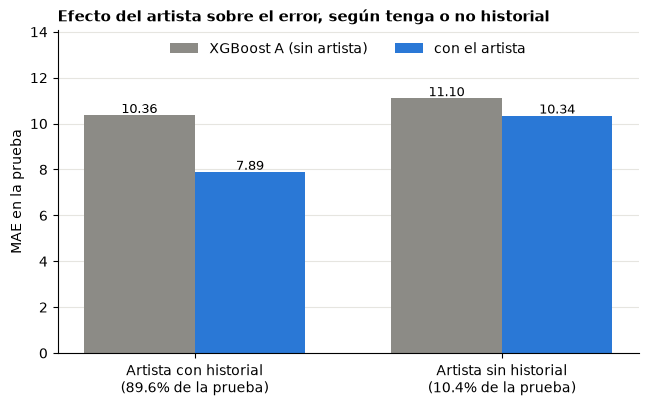

In [27]:
# ---------- Figura: el artista ayuda mucho más a quienes tienen historial (MAE en la prueba)
grupos = [('Artista con historial\n(%.1f%% de la prueba)' % (conocido.mean() * 100), conocido), ('Artista sin historial\n(%.1f%% de la prueba)' % ((~conocido).mean() * 100), ~conocido)]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(2)
sin_art = [mean_absolute_error(y_test[m], base_te[m]) for _, m in grupos]
con_art = [mean_absolute_error(y_test[m], p_art_te[m]) for _, m in grupos]
b1 = ax.bar(x - 0.18, sin_art, width=0.36, color='#8c8b86', label='XGBoost A (sin artista)')
b2 = ax.bar(x + 0.18, con_art, width=0.36, color='#2a78d6', label='con el artista')
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f'{b.get_height():.2f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([g[0] for g in grupos]); ax.set_ylabel('MAE en la prueba'); ax.set_ylim(0, max(sin_art + con_art) + 3)
ax.set_title('Efecto del artista sobre el error, según tenga o no historial', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, loc='upper center', ncol=2); ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '7_2_artista.png', dpi=110, bbox_inches='tight'); plt.show()

**Resultado.** El artista es **el cambio más grande de todo el trabajo**, mayor que cualquier ajuste de hiperparámetros:

| | R² | RMSE | MAE | MAE en éxitos | Equidad | Criterios (prueba) |
|---|---|---|---|---|---|---|
| XGBoost A | 0,410 | 15,468 | 10,438 | 29,036 | 3,751 | 4 |
| Con el artista | **0,558** | **13,388** | **8,140** | **22,762** | **2,520** | 4 |

En validación el MAE baja de 10,346 a 8,084 (−2,262, unas 30 veces el ruido). En la prueba baja 2,298 puntos, contra los 0,205 que aportó toda la optimización de hiperparámetros. El error en éxitos baja a 22,8, lo más cerca del límite de 20 que hemos estado. Siguen fallando la brecha (0,288) y los éxitos.

**Respuesta a H7: se cumple, con un matiz.** El 89,6% de las canciones de prueba (15.377 de 17.155) tiene un artista con otras canciones en el entrenamiento, y para ellas el MAE baja de 10,362 a 7,885 (−2,477). Para las 1.778 restantes, artistas sin historial, el MAE baja de 11,096 a 10,339 (−0,757): una mejora tres veces menor. La ganancia sale sobre todo de conocer al artista.

**Qué significa esto, y qué no.** Que conocer al artista sea tan informativo nos dice que, en estos datos, **el nombre del artista pesa por sí solo en la popularidad de una canción**: el modelo con artista predice, en buena parte, la fama del artista más que la canción, y por eso ayuda mucho a quien ya es conocido y poco a quien no. Ese es el efecto superestrella que sospechábamos, y es la razón por la que el artista se había excluido del modelo (a eso se suma la privacidad). Hay que ser precisos en el alcance: lo que medimos es esa dependencia, no si perjudica a los artistas nuevos en una decisión real. Para eso habría que revisar el error del modelo por nivel de fama del artista, y no lo hicimos. Tampoco podemos decir que el nombre cause la popularidad: es una señal de todo lo que el artista trae (fama, seguidores, promoción). Por eso el artista queda como diagnóstico y no como parte de la solución: decidir si se usa es una decisión de negocio y de ética, no un ajuste del modelo.

---
# 8. Selección de la solución y tabla comparativa final

## 8.1 Comparación final: hiperparámetros por defecto contra optimizados

Esta tabla contesta la pregunta central de la evaluación: **¿mejoraron los modelos al optimizar sus hiperparámetros?** Cada modelo aparece con sus hiperparámetros por defecto (los de la EV2) y con los optimizados, medidos de la misma forma: en validación cruzada (con el ruido entre folds) y, una sola vez, en la prueba. Al final se agrega el XGBoost de pérdida absoluta del experimento 7.1, solo como comparación.

Las versiones "optimizado (regla)" y "optimizado (menor MAE)" son los dos finalistas de cada modelo: el que cumple más criterios y el de menor error de validación. Cuando son el mismo candidato aparece una sola fila.

In [28]:
# ---------- Tabla comparativa final: validación (media de 5 folds) y prueba (una sola vez)
def val(r):
    return {'MAE valid.': r['MAE'], 'ruido': r['ruido'], 'R2 valid.': r['R2'], 'RMSE valid.': r['RMSE'], 'brecha valid.': r['brecha_R2'], 'criterios valid.': int(r['criterios'])}
def pru(r):
    return {'MAE prueba': r['MAE'], 'R2 prueba': r['R2'], 'RMSE prueba': r['RMSE'], 'brecha prueba': r['brecha_R2'], 'MAE éxitos': r['MAE_exitos'],
            'equidad': r['brecha_cuartiles'], 'criterios prueba': int(r['criterios'])}

filas = []
for t in NOMBRES:
    filas.append({'modelo': NOMBRES[t], 'versión': 'por defecto', **val(DEFECTO[t]), **pru(PRUEBA_DEFECTO.loc[f'{NOMBRES[t]} (por defecto)'])})
    for tipo, etiqueta in [('más criterios', 'optimizado (regla)'), ('menor MAE', 'optimizado (menor MAE)')]:
        if (t, tipo) in FINALISTAS:
            filas.append({'modelo': NOMBRES[t], 'versión': etiqueta, **val(FINALISTAS[(t, tipo)]), **pru(PRUEBA.loc[f'{NOMBRES[t]} ({tipo})'])})
prueba_exp = pd.DataFrame(FILAS_PRUEBA).set_index('candidato')
filas.append({'modelo': 'XGBoost, pérdida absoluta (B)', 'versión': 'optimizado (menor MAE)', **val(MEJOR_ABS_MAE), **pru(prueba_exp.loc['XGBoost B: pérdida absoluta'])})
COMPARATIVA = pd.DataFrame(filas).set_index(['modelo', 'versión'])
display(UMBRAL_TXT)
display(COMPARATIVA)

,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
UMBRAL,">= 0,40",<= 15.51,<= 13.46,"<= 0,05",<= 20,<= 5


MAE valid.  ruido  R2 valid.  RMSE valid.  brecha valid.  criterios valid.  MAE prueba  R2 prueba  RMSE prueba  \
modelo                        versión                                                                                                                                  
Ridge                         por defecto                 11.469  0.046      0.353       16.130          0.000                 3      11.516      0.348       16.267   
                              optimizado (regla)          11.469  0.046      0.353       16.130          0.000                 3      11.516      0.348       16.267   
Random Forest                 por defecto                 10.828  0.079      0.393       15.622          0.528                 2      10.846      0.388       15.756   
                              optimizado (regla)          12.613  0.043      0.303       16.742          0.047                 3      12.735      0.296       16.896   
                              optimizado (menor MAE)      10.828  0.079      0.393       15.622          0.528                 2      10.846      0.388       15.756   
XGBoost                       por defecto                 10.655  0.085      0.390       15.663          0.288                 2      10.643      0.386       15.788   
                              optimizado (regla)          10.346  0.073      0.417       15.303          0.401                 4      10.438      0.410       15.468   
XGBoost, pérdida absoluta (B) optimizado (menor MAE)       9.831  0.088      0.398       15.551          0.160                 2       9.926      0.383       15.819   

                                                      brecha prueba  MAE éxitos  equidad  criterios prueba  
modelo                        versión                                                                       
Ridge                         por defecto                     0.005      32.821    4.408                 3  
                              optimizado (regla)              0.005      32.821    4.408                 3  
Random Forest                 por defecto                     0.533      29.950    3.940                 2  
                              optimizado (regla)              0.045      34.515    5.458                 2  
                              optimizado (menor MAE)          0.533      29.950    3.940                 2  
XGBoost                       por defecto                     0.265      29.360    3.984                 2  
                              optimizado (regla)              0.388      29.036    3.751                 4  
XGBoost, pérdida absoluta (B) optimizado (menor MAE)          0.159      29.273    4.124                 2

**Nota.** Los hiperparámetros por defecto y los optimizados se miden con las **mismas tablas, los mismos folds y la misma prueba**, así que la diferencia entre sus filas es el efecto de los hiperparámetros y de nada más.

In [29]:
# ---------- Cuánto cambió cada modelo al optimizar (en la prueba y en validación) y si el cambio supera el ruido
filas = []
for t in NOMBRES:
    d = COMPARATIVA.loc[(NOMBRES[t], 'por defecto')]
    for tipo, etiqueta in [('más criterios', 'optimizado (regla)'), ('menor MAE', 'optimizado (menor MAE)')]:
        if (NOMBRES[t], etiqueta) in COMPARATIVA.index:
            o = COMPARATIVA.loc[(NOMBRES[t], etiqueta)]
            filas.append({'modelo': NOMBRES[t], 'versión optimizada': etiqueta,
                          'cambio MAE valid.': o['MAE valid.'] - d['MAE valid.'], 'ruido': d['ruido'], 'veredicto valid.': veredicto(o['MAE valid.'] - d['MAE valid.'], d['ruido']),
                          'cambio MAE prueba': o['MAE prueba'] - d['MAE prueba'], 'cambio R2 prueba': o['R2 prueba'] - d['R2 prueba'],
                          'cambio RMSE prueba': o['RMSE prueba'] - d['RMSE prueba'], 'cambio brecha prueba': o['brecha prueba'] - d['brecha prueba'],
                          'cambio criterios prueba': int(o['criterios prueba'] - d['criterios prueba'])})
CAMBIOS = pd.DataFrame(filas).set_index(['modelo', 'versión optimizada'])
display(CAMBIOS)

cambio MAE valid.  ruido veredicto valid.  cambio MAE prueba  cambio R2 prueba  cambio RMSE prueba  cambio brecha prueba  \
modelo        versión optimizada                                                                                                                                 
Ridge         optimizado (regla)                 -0.000  0.046       sin efecto             -0.000             0.000              -0.000                -0.000   
Random Forest optimizado (regla)                  1.784  0.079          empeora              1.889            -0.092               1.140                -0.488   
              optimizado (menor MAE)              0.000  0.079       sin efecto              0.000             0.000               0.000                 0.000   
XGBoost       optimizado (regla)                 -0.309  0.085           mejora             -0.205             0.025              -0.320                 0.123   

                                      cambio criterios prueba  
modelo        versión optimizada                               
Ridge         optimizado (regla)                            0  
Random Forest optimizado (regla)                            0  
              optimizado (menor MAE)                        0  
XGBoost       optimizado (regla)                            2

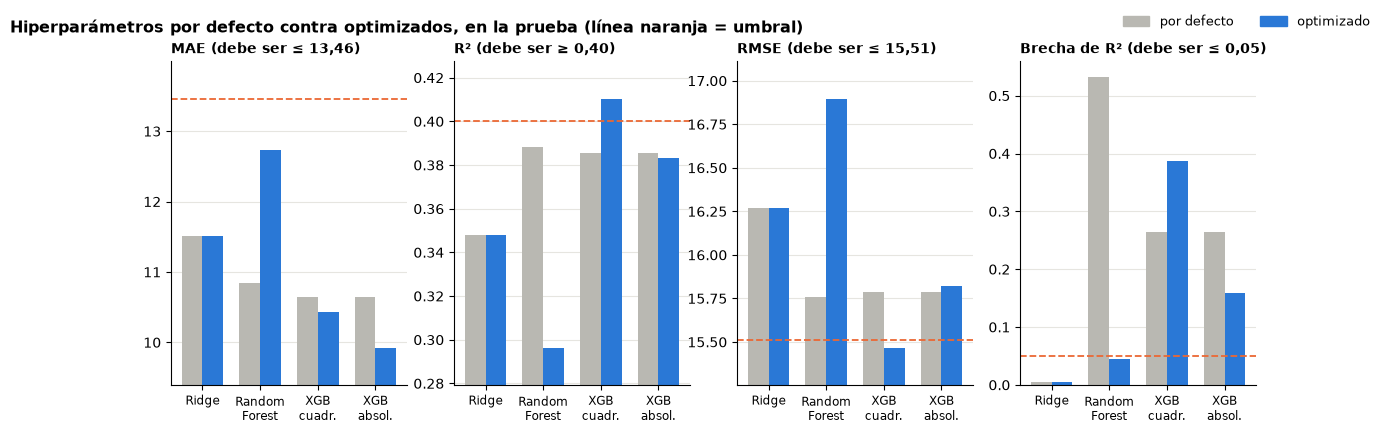

In [30]:
# ---------- Figura: por defecto contra optimizado en la prueba (línea naranja = umbral; el eje no parte de cero para que se vea la diferencia)
from matplotlib.patches import Patch
datos_fig = [('Ridge', COMPARATIVA.loc[('Ridge', 'por defecto')], COMPARATIVA.loc[('Ridge', 'optimizado (regla)')]),
             ('Random\nForest', COMPARATIVA.loc[('Random Forest', 'por defecto')], COMPARATIVA.loc[('Random Forest', 'optimizado (regla)')]),
             ('XGB\ncuadr.', COMPARATIVA.loc[('XGBoost', 'por defecto')], COMPARATIVA.loc[('XGBoost', 'optimizado (regla)')]),
             ('XGB\nabsol.', COMPARATIVA.loc[('XGBoost', 'por defecto')], COMPARATIVA.loc[('XGBoost, pérdida absoluta (B)', 'optimizado (menor MAE)')])]
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
for ax, col, titulo, umbral in [(axes[0], 'MAE prueba', 'MAE (debe ser ≤ 13,46)', UMBRALES['MAE']), (axes[1], 'R2 prueba', 'R² (debe ser ≥ 0,40)', UMBRALES['R2']),
                                (axes[2], 'RMSE prueba', 'RMSE (debe ser ≤ 15,51)', UMBRALES['RMSE']), (axes[3], 'brecha prueba', 'Brecha de R² (debe ser ≤ 0,05)', UMBRALES['brecha_R2'])]:
    x = np.arange(len(datos_fig))
    vd, vo = [d[col] for _, d, _ in datos_fig], [o[col] for _, _, o in datos_fig]
    ax.bar(x - 0.18, vd, width=0.36, color='#b9b8b2')
    ax.bar(x + 0.18, vo, width=0.36, color='#2a78d6')
    ax.axhline(umbral, color='#eb6834', linestyle='--', linewidth=1.3)
    if col != 'brecha prueba':
        v = vd + vo + [umbral]; m = (max(v) - min(v)) * 0.15
        ax.set_ylim(min(v) - m, max(v) + m)
    ax.set_xticks(x); ax.set_xticklabels([e for e, _, _ in datos_fig], fontsize=8.5)
    ax.set_title(titulo, loc='left', fontsize=10, fontweight='bold'); ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.legend(handles=[Patch(color='#b9b8b2', label='por defecto'), Patch(color='#2a78d6', label='optimizado')], frameon=False, fontsize=9.5, loc='upper right', ncol=2, bbox_to_anchor=(0.99, 1.02))
fig.suptitle('Hiperparámetros por defecto contra optimizados, en la prueba (línea naranja = umbral)', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '8_1_defecto_contra_optimizado.png', dpi=110, bbox_inches='tight'); plt.show()

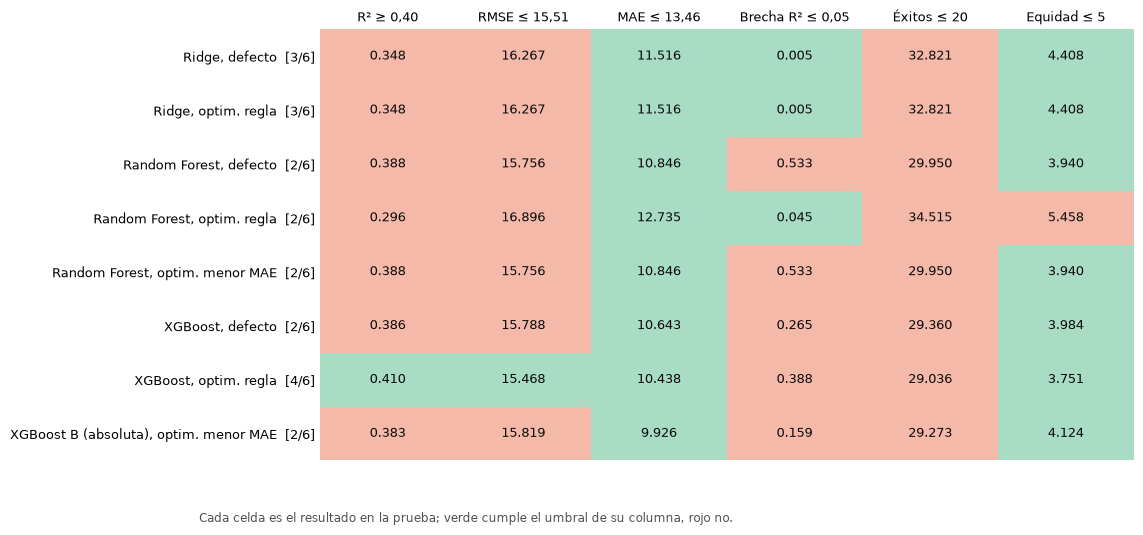

In [31]:
# ---------- Figura: qué criterios cumple cada versión en la prueba (verde = cumple, rojo = no cumple)
from matplotlib.colors import ListedColormap
CAND = COMPARATIVA[['R2 prueba', 'RMSE prueba', 'MAE prueba', 'brecha prueba', 'MAE éxitos', 'equidad', 'criterios prueba']].copy()
CAND.columns = ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles', 'criterios']
cols = ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles']
etiquetas_cols = ['R² ≥ 0,40', 'RMSE ≤ 15,51', 'MAE ≤ 13,46', 'Brecha R² ≤ 0,05', 'Éxitos ≤ 20', 'Equidad ≤ 5']
ok = np.array([[r['R2'] >= UMBRALES['R2'], r['RMSE'] <= UMBRALES['RMSE'], r['MAE'] <= UMBRALES['MAE'], r['brecha_R2'] <= UMBRALES['brecha_R2'],
                r['MAE_exitos'] <= UMBRALES['MAE_exitos'], r['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']] for _, r in CAND.iterrows()])
NOMBRES_FILAS = {'Ridge': 'Ridge', 'Random Forest': 'Random Forest', 'XGBoost': 'XGBoost', 'XGBoost, pérdida absoluta (B)': 'XGBoost B (absoluta)'}
VERSIONES = {'por defecto': 'defecto', 'optimizado (regla)': 'optim. regla', 'optimizado (menor MAE)': 'optim. menor MAE'}
nombres_filas = [f'{NOMBRES_FILAS[m]}, {VERSIONES[v]}  [{int(k)}/6]' for (m, v), k in zip(CAND.index, CAND['criterios'])]
fig, ax = plt.subplots(figsize=(10.5, 0.5 * len(CAND) + 1.6))
ax.imshow(ok, cmap=ListedColormap(['#f4b9a8', '#a8dcc4']), aspect='auto')
for i in range(ok.shape[0]):
    for j, c in enumerate(cols):
        ax.text(j, i, f"{CAND.iloc[i][c]:.3f}", ha='center', va='center', fontsize=9.5, color='#0b0b0b')
ax.set_xticks(range(6)); ax.set_xticklabels(etiquetas_cols, fontsize=9); ax.xaxis.tick_top()
ax.set_yticks(range(ok.shape[0])); ax.set_yticklabels(nombres_filas, fontsize=9)
for lado in ax.spines.values(): lado.set_visible(False)
ax.tick_params(length=0)
fig.text(0.01, 0.0, 'Cada celda es el resultado en la prueba; verde cumple el umbral de su columna, rojo no.', fontsize=8.5, color='#52514e')
fig.savefig(IMAGENES / '8_2_criterios_por_candidato.png', dpi=110, bbox_inches='tight'); plt.show()

**Qué cambió al optimizar, modelo por modelo.**

- **Ridge: nada.** Mismo MAE en validación (11,469) y en prueba (11,516), y los mismos 3 criterios.
- **Random Forest: empeora o queda igual.** La versión que elige la regla baja la brecha de R² de 0,533 a 0,045, pero el MAE de prueba sube de 10,846 a 12,735 (+1,889) y los criterios siguen en 2 (gana la brecha y pierde la equidad). La versión de menor MAE es la de fábrica, o sea que no hay nada mejor que lo que ya teníamos.
- **XGBoost de pérdida cuadrática: mejora, pero poco.** El MAE de validación baja de 10,655 a 10,346 (−0,309, unas 3,6 veces el ruido) y el de prueba de 10,643 a 10,438 (−0,205, un 2%). El R² sube de 0,386 a 0,410 y el RMSE baja de 15,788 a 15,468, con lo que cruza esos dos umbrales y pasa de 2 a 4 criterios. Lo que empeora es la brecha de R² (de 0,265 a 0,388).
- **XGBoost de pérdida absoluta (B)**, como comparación, tiene el menor MAE de todos (9,926) pero R² y RMSE fuera de sus umbrales: 2 criterios.

**Lectura de las figuras.** En las barras, el único cambio grande entre gris y azul es el del Random Forest, y es para peor. En XGBoost cuadrático la mejora se ve, pero es chica, y la barra de la brecha sube. En el mapa de criterios, **R² y RMSE están en verde solo para XGBoost optimizado**; la brecha de R² está en verde solo para Ridge y para el Random Forest podado (que la cumplen porque no memorizan, no porque predigan bien); el error en éxitos está en rojo en todas las filas, sin excepción; y el MAE está en verde en todas.

**¿Valió la pena optimizar?** Para dos de los tres modelos, no: Ridge no cambió y el Random Forest no pudo mejorar a su versión de fábrica. Para XGBoost, la mejora es real pero modesta: 2% de MAE y dos criterios más, que se cumplen por márgenes cortos (0,010 en R² y 0,045 en RMSE). Eso también es un resultado: nos dice que los valores por defecto ya estaban cerca de lo que estos datos permiten, y que el techo no está en los hiperparámetros.

## 8.2 Decisión y justificación

**Se elige el XGBoost de pérdida cuadrática con los hiperparámetros que dejó la búsqueda** (profundidad 10, tasa de aprendizaje de 0,0125, 1.134 árboles). Es un solo modelo. Cómo se llegó a esa decisión:

**Es el que cumple más criterios, en validación y en la prueba.** La regla de la sección 1.2 se fijó antes de buscar: gana el que cumple más criterios y, en un empate, el de menor MAE de validación. En validación cumple 4; en la prueba también 4 (R², RMSE, MAE y equidad). Ningún otro candidato pasa de 3: Ridge cumple 3 (MAE, brecha y equidad), el Random Forest 2 y el XGBoost de pérdida absoluta 2. La prueba no se usó para elegir, solo para confirmar.

**Por qué no la pérdida absoluta.** El XGBoost B tiene mejor MAE (9,926 contra 10,438), pero incumple R² y RMSE, dos de los seis criterios, y como esas dos medidas castigan los errores grandes y la pérdida absoluta no, es lo esperable (sección 7.1). Si el criterio fuera solo el MAE, ganaría B; con los seis criterios que fijamos al inicio, gana la cuadrática.

**Por qué no Ridge, aunque cumple 3.** Cumple la brecha de R² (0,005) porque casi no aprende: su R² es 0,348 y no alcanza el umbral. Un criterio cumplido no es lo mismo que predecir bien, y Ridge no cruza los umbrales de R² ni de RMSE.

**Lo que hay que decir con honestidad.**

- **La mejora frente al XGBoost por defecto es chica.** El MAE baja 0,2 (un 2%) y se ganan dos criterios que se cumplen por márgenes cortos: R² por 0,010 y RMSE por 0,045. Con otros datos podrían quedar fuera.
- **Cuesta complejidad y empeora la brecha.** El modelo por defecto usa 100 árboles de profundidad 6; el elegido, 1.134 de profundidad 10, y su brecha de R² es 0,388 contra 0,265. Para quien prefiera la simplicidad, el XGBoost por defecto (MAE 10,643, 2 criterios) es una alternativa defendible.
- **No cumple dos criterios.** La brecha de R² (0,388) y el error en canciones de popularidad ≥ 70 (29,0), y ningún candidato, ni los de los experimentos, cumple los seis.
- **Hay optimismo en la validación.** Se eligió entre 122 candidatos de XGBoost, así que sus cifras de validación están algo infladas: en la prueba el MAE sube 0,09 y el RMSE 0,17. La prueba, usada una sola vez, es la cifra a reportar.

En la tabla de abajo (sección 11) se pueden ver los seis criterios del modelo elegido.

## 8.3 Guardar la solución final

In [32]:
# ---------- La solución elegida en 8.2: el XGBoost de pérdida cuadrática que dejó la búsqueda (A), ya entrenado con todo el entrenamiento
SOLUCION = 'XGBoost de pérdida cuadrática (optimizado)'
final = AJUSTADOS[('xgb', 'más criterios')]
joblib.dump({'modelo': final, 'generos': GENEROS,
             'descripcion': 'XGBRegressor de perdida cuadratica con los hiperparametros que dejo la busqueda. Recibe la tabla xgb de la EV2 '
                            '(15 variables y track_genre como categoria nativa, con las categorias de la lista generos).'},
            MODELOS / 'modelo_final_ev3.joblib', compress=('zlib', 6))
with open(MODELOS / 'modelo_final_ev3.json', 'w', encoding='utf-8') as f:
    json.dump({'modelo': SOLUCION, 'hiperparametros': {k: nativo(v) for k, v in PARAMS_A.items()}, 'dispositivo': DISPOSITIVO,
               'metricas_prueba': {k: float(v) for k, v in CAND.loc[('XGBoost', 'optimizado (regla)'), ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles']].items()}},
              f, ensure_ascii=False, indent=2)

# Comprobación: el modelo guardado, vuelto a leer, da lo mismo en la prueba
leido = joblib.load(MODELOS / 'modelo_final_ev3.joblib')['modelo']
print('MAE de prueba del modelo guardado:', round(float(mean_absolute_error(y_test, leido.predict(XTE['xgb']))), 4), '| MAE de prueba medido antes:', round(float(PRUEBA.loc['XGBoost (más criterios)', 'MAE']), 4))
print('Guardado en models/: modelo_final_ev3.joblib y modelo_final_ev3.json')

MAE de prueba del modelo guardado: 10.4377 | MAE de prueba medido antes: 10.4377
Guardado en models/: modelo_final_ev3.joblib y modelo_final_ev3.json


**Nota.** El modelo final es un solo `XGBRegressor`. Recibe la tabla de XGBoost de la EV2 (15 variables ya preparadas y el género como categoría), que para canciones nuevas se obtiene con el preprocesador exportado en `preprocesadores_ev2.joblib`. Se vuelve a leer y se mide en la prueba para comprobar que lo guardado es lo mismo que se evaluó.

---
# 9. Errores e interpretación de la solución final

## 9.1 Error por segmento de popularidad (prueba)

In [33]:
# ---------- Error por segmento de popularidad: solución final contra la línea base (predice siempre la media del entrenamiento) y contra el XGBoost por defecto
pred = final.predict(XTE['xgb'])
pred_def = AJUSTADOS[('xgb', 'defecto')].predict(XTE['xgb'])
base = np.full(len(y_test), y_train.mean())
segs = {'Popularidad 0': y_test == 0, 'Popularidad 1 a 69': (y_test > 0) & (y_test < 70), 'Popularidad 70 o más': y_test >= 70}
filas = []
for nombre, mask in segs.items():
    filas.append({'segmento': nombre, 'canciones': int(mask.sum()), 'MAE línea base': mean_absolute_error(y_test[mask], base[mask]),
                  'MAE XGBoost por defecto': mean_absolute_error(y_test[mask], pred_def[mask]), 'MAE solución final': mean_absolute_error(y_test[mask], pred[mask]),
                  'sesgo de la solución (pred - real)': (pred[mask] - y_test[mask]).mean()})
display(pd.DataFrame(filas).set_index('segmento'))

e = np.abs(y_test.values - pred)
display(pd.DataFrame({'error medio (MAE)': [e.mean()], 'error mediano': [np.median(e)], '% con error <= 5 puntos': [(e <= 5).mean() * 100],
                      '% con error <= 10 puntos': [(e <= 10).mean() * 100], '% con error <= 20 puntos': [(e <= 20).mean() * 100], '% con error > 30 puntos': [(e > 30).mean() * 100]},
                     index=['solución final']))
print('Éxitos subestimados:', f"{(pred[y_test.values >= 70] < y_test.values[y_test.values >= 70]).mean() * 100:.1f}%", '| canciones de popularidad 0 sobrestimadas:', f"{(pred[y_test.values == 0] > 0).mean() * 100:.1f}%")

,canciones,MAE línea base,MAE XGBoost por defecto,MAE solución final,sesgo de la solución (pred - real)
segmento,,,,,
Popularidad 0,1316,34.323,25.278,25.711,25.691
Popularidad 1 a 69,15182,14.254,8.564,8.309,-0.586
Popularidad 70 o más,657,41.194,29.360,29.036,-29.024


,error medio (MAE),error mediano,% con error <= 5 puntos,% con error <= 10 puntos,% con error <= 20 puntos,% con error > 30 puntos
solución final,10.438,6.260,42.384,65.299,84.133,7.426


Éxitos subestimados: 99.4% | canciones de popularidad 0 sobrestimadas: 98.3%


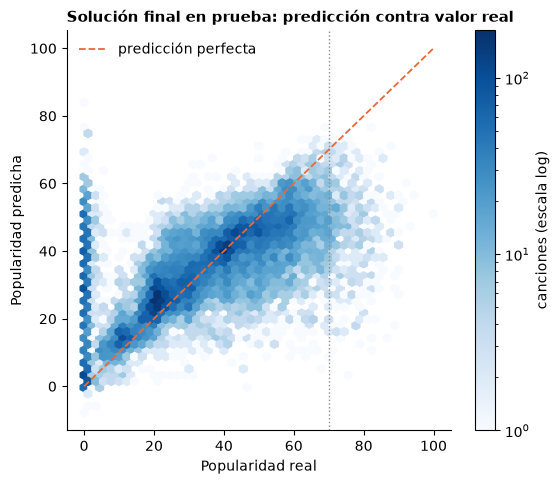

In [34]:
# ---------- Figura: predicción contra valor real (los éxitos quedan por debajo de la diagonal)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
hb = ax.hexbin(y_test, pred, gridsize=45, cmap='Blues', mincnt=1, bins='log')
ax.plot([0, 100], [0, 100], color='#eb6834', linestyle='--', linewidth=1.3, label='predicción perfecta')
ax.axvline(CORTE_EXITO, color='#8c8b86', linestyle=':', linewidth=1)
ax.set_xlabel('Popularidad real'); ax.set_ylabel('Popularidad predicha')
ax.set_title('Solución final en prueba: predicción contra valor real', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, loc='upper left'); fig.colorbar(hb, label='canciones (escala log)')
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '9_1_prediccion_contra_real.png', dpi=110, bbox_inches='tight'); plt.show()

## 9.2 Qué usa el modelo final

In [35]:
# ---------- Importancia de las variables: ganancia de cada variable en los árboles del modelo final
s = pd.Series(final.get_booster().get_score(importance_type='gain')).reindex(list(XTR['xgb'].columns)).fillna(0)
imp = (s / s.sum() * 100).sort_values(ascending=False).to_frame('importancia (%)')
display(imp.head(10))

,importancia (%)
track_genre,19.938
es_instrumental,13.545
explicit,8.945
n_generos,8.862
n_artistas,6.104
acousticness,4.366
loudness,4.312
energy,4.210
duracion_min,4.126
danceability,4.064


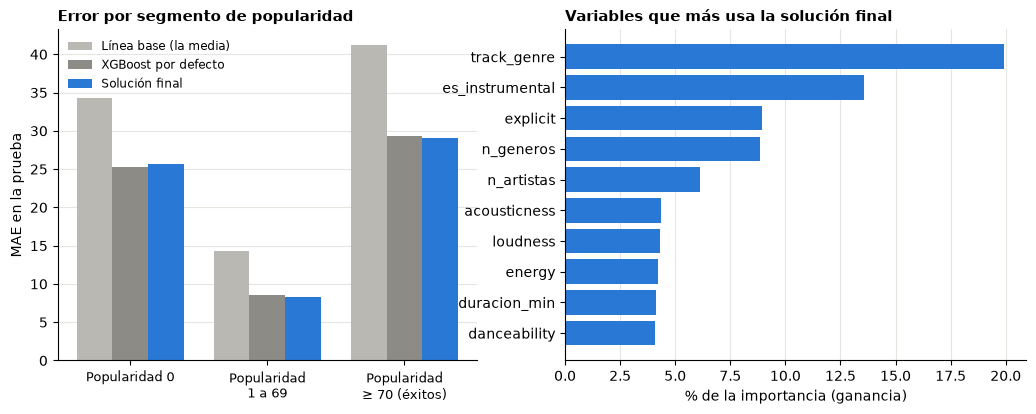

In [36]:
# ---------- Figura: error por segmento (izquierda) e importancia de las variables (derecha)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={'width_ratios': [1, 1.1]})
tabla_seg = pd.DataFrame({n: [mean_absolute_error(y_test[m], base[m]), mean_absolute_error(y_test[m], pred_def[m]), mean_absolute_error(y_test[m], pred[m])] for n, m in segs.items()},
                         index=['Línea base (la media)', 'XGBoost por defecto', 'Solución final']).T
x = np.arange(3)
for k, (col, c) in enumerate(zip(tabla_seg.columns, ['#b9b8b2', '#8c8b86', '#2a78d6'])):
    axes[0].bar(x + (k - 1) * 0.26, tabla_seg[col], width=0.26, color=c, label=col)
axes[0].set_xticks(x); axes[0].set_xticklabels(['Popularidad 0', 'Popularidad\n1 a 69', 'Popularidad\n≥ 70 (éxitos)'], fontsize=9)
axes[0].set_ylabel('MAE en la prueba'); axes[0].legend(frameon=False, fontsize=8.5)
axes[0].set_title('Error por segmento de popularidad', loc='left', fontsize=10.5, fontweight='bold')
top = imp['importancia (%)'].head(10)[::-1]
axes[1].barh(top.index, top.values, color='#2a78d6')
axes[1].set_xlabel('% de la importancia (ganancia)'); axes[1].set_title('Variables que más usa la solución final', loc='left', fontsize=10.5, fontweight='bold')
for ax in axes:
    ax.grid(axis='x' if ax is axes[1] else 'y', color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '9_2_error_e_importancia.png', dpi=110, bbox_inches='tight'); plt.show()

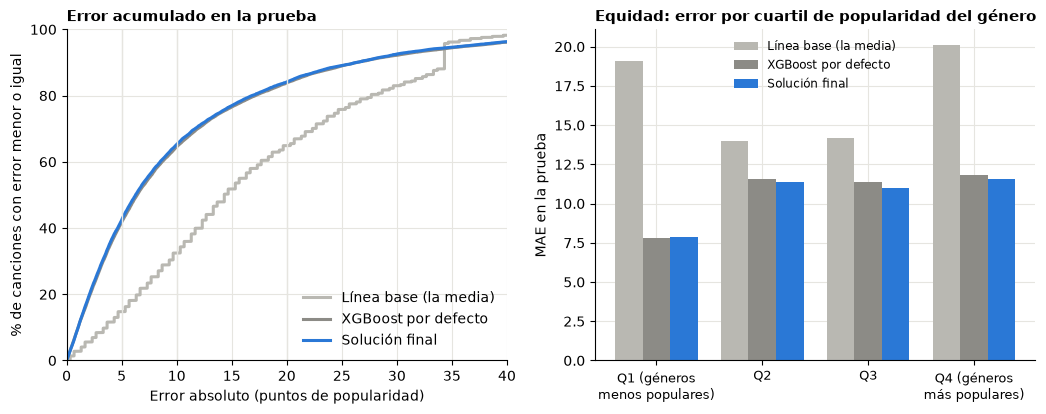

Brecha entre cuartiles (equidad): línea base 6.077 | por defecto 3.984 | solución final 3.751
MAE por cuartil (solución final): [7.84, 11.35, 11.02, 11.59]


In [37]:
# ---------- Figura: error acumulado (qué porcentaje de canciones queda dentro de cada error) y equidad entre cuartiles de género
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for nombre, p, c in [('Línea base (la media)', base, '#b9b8b2'), ('XGBoost por defecto', pred_def, '#8c8b86'), ('Solución final', pred, '#2a78d6')]:
    errores = np.sort(np.abs(y_test.values - p))
    axes[0].plot(errores, np.arange(1, len(errores) + 1) / len(errores) * 100, color=c, linewidth=2.2, label=nombre)
for u in (5, 10, 20):
    axes[0].axvline(u, color='#e6e5e0', linewidth=1)
axes[0].set_xlim(0, 40); axes[0].set_ylim(0, 100); axes[0].set_xlabel('Error absoluto (puntos de popularidad)'); axes[0].set_ylabel('% de canciones con error menor o igual')
axes[0].set_title('Error acumulado en la prueba', loc='left', fontsize=10.5, fontweight='bold'); axes[0].legend(frameon=False, loc='lower right')
cuartil_test = pd.qcut(GENERO_TE.map(MEDIA_GENERO).values, q=4, labels=False)
q = np.arange(4)
for k, (nombre, p, c) in enumerate([('Línea base (la media)', base, '#b9b8b2'), ('XGBoost por defecto', pred_def, '#8c8b86'), ('Solución final', pred, '#2a78d6')]):
    axes[1].bar(q + (k - 1) * 0.26, pd.Series(np.abs(y_test.values - p)).groupby(cuartil_test).mean().values, width=0.26, color=c, label=nombre)
axes[1].set_xticks(q); axes[1].set_xticklabels(['Q1 (géneros\nmenos populares)', 'Q2', 'Q3', 'Q4 (géneros\nmás populares)'], fontsize=9)
axes[1].set_ylabel('MAE en la prueba'); axes[1].set_title('Equidad: error por cuartil de popularidad del género', loc='left', fontsize=10.5, fontweight='bold')
axes[1].legend(frameon=False, fontsize=8.5)
for ax in axes:
    ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '9_3_error_acumulado_y_equidad.png', dpi=110, bbox_inches='tight'); plt.show()
print('Brecha entre cuartiles (equidad): línea base', round(pd.Series(np.abs(y_test.values - base)).groupby(cuartil_test).mean().agg(lambda s: s.max() - s.min()), 3),
      '| por defecto', round(pd.Series(np.abs(y_test.values - pred_def)).groupby(cuartil_test).mean().agg(lambda s: s.max() - s.min()), 3),
      '| solución final', round(pd.Series(np.abs(y_test.values - pred)).groupby(cuartil_test).mean().agg(lambda s: s.max() - s.min()), 3))
print('MAE por cuartil (solución final):', pd.Series(np.abs(y_test.values - pred)).groupby(cuartil_test).mean().round(2).tolist())

**Dónde se equivoca (9.1).** La solución baja el error frente a la línea base en los tres segmentos, y frente al XGBoost por defecto solo en las canciones de popularidad media (8,564 a 8,309) y en los éxitos (29,360 a 29,036); en las de popularidad 0 queda un poco peor (25,278 a 25,711). El patrón de fondo es el de siempre:

- En las canciones de **popularidad 0** (1.316) predice demasiado alto: sesgo de +25,7 puntos, y sobrestima el 98,3% de ellas.
- En las de **1 a 69** (15.182, el grueso) hace bien su trabajo: MAE 8,309 contra 14,254 de la línea base, con un sesgo casi nulo (−0,6).
- En los **éxitos** (657) el sesgo es de −29,0, casi igual al MAE: **subestima el 99,4% de los éxitos**. Es lo que impide cumplir el criterio 5, y ningún hiperparámetro lo arregla, porque el modelo tiende hacia la media y los éxitos están en la cola.

En puntos: el error mediano es 6,26, el 42,4% de las canciones queda a 5 puntos o menos, el 65,3% a 10 o menos y el 84,1% a 20 o menos, y el 7,4% se equivoca en más de 30. En el gráfico de equidad, la brecha entre el cuartil de géneros con mayor error y el de menor es 3,751 (bajo el umbral de 5), contra 6,077 de la línea base y 3,984 del XGBoost por defecto. Los géneros menos populares (Q1) son los que mejor predice (MAE 7,84); los otros tres cuartiles quedan entre 11,0 y 11,6.

**Qué usa el modelo (9.2).** El género concentra casi la quinta parte de la importancia (19,9%), seguido de `es_instrumental` (13,5%), `explicit` (8,9%), `n_generos` (8,9%) y `n_artistas` (6,1%); las variables de audio aportan entre 4,1% y 4,4% cada una. La importancia por ganancia indica qué variables usa el modelo para dividir, no que causen la popularidad. La conclusión de la EV1, que el género pesa mucho y el audio poco, se mantiene. Una advertencia práctica: `n_generos` solo existe cuando la canción ya está publicada, así que para decidir antes del lanzamiento habría que reentrenar sin ella.

---
# 10. Conclusiones, limitaciones y recomendaciones

## 10.1 Respuesta a la pregunta central

> **¿Se pueden encontrar hiperparámetros que cumplan los seis criterios de éxito?** **No.** El máximo es **4 de 6**, con XGBoost optimizado. Siempre fallan la **brecha de R²** y el **error en éxitos**.

**¿Mejoraron los modelos al optimizarlos?** Solo uno de tres, y por poco. XGBoost pasó de 2 a 4 criterios en la prueba (MAE 10,643 a 10,438; R² 0,386 a 0,410; RMSE 15,788 a 15,468). Ridge no cambió, y el Random Forest empeora cuando se le exige cumplir la brecha: su mejor versión es la de fábrica.

## 10.2 Respuesta a cada pregunta

| # | Pregunta | Respuesta | Evidencia |
|---|---|---|---|
| H1 | ¿Ajustar mejora el error de los tres modelos? | **Solo en XGBoost** | −0,309 de MAE en validación (3,6 veces el ruido); Ridge sin efecto; Random Forest empeora o queda igual |
| H2 | ¿Algún modelo cumple los seis criterios? | **No** | Máximo de 4 criterios, en validación y en prueba |
| H3 | ¿Se puede reducir el sobreajuste del Random Forest sin que el error suba? | **No** | Cumplir la brecha cuesta MAE: Random Forest +1,785; XGBoost cuadrático +0,602; con pérdida absoluta solo +0,2 |
| H4 | ¿El Grid agrega una mejora que valga lo que cuesta? | **No** | −0,023 de MAE en XGBoost (0,3 veces el ruido), a 4 veces el tiempo |
| H5 | ¿Los resultados del ganador se mantienen en la prueba? | **Casi: salen algo peores** | MAE +0,092 y RMSE +0,165; el Random Forest pierde el criterio que cumplía por 0,077 |
| H6 | ¿La pérdida absoluta logra menos error que la cuadrática, y qué se pierde? | **Menos MAE, pero pierde R² y RMSE** | MAE −0,5; R² −0,027; su brecha (0,159) resultó menor que la de A (0,388) |
| H7 | ¿Cuánto mejora el modelo si conoce al artista? | **Mucho, y depende del historial** | MAE −2,3 en la prueba; −2,5 con historial y −0,8 sin él |

## 10.3 ¿Es un buen predictor?

Reduce el error un 38% frente a predecir siempre la media (MAE 10,4 contra 16,8), acierta a 10 puntos o menos en dos de cada tres canciones y explica el 41% de la variación. Sirve para ordenar canciones de popularidad media o baja. No sirve para detectar éxitos: subestima el 99,4% de ellos, con unos 29 puntos de error. La causa no está en los hiperparámetros sino en la información: toda la optimización bajó el MAE 0,2, y agregar el artista lo bajó 2,3. Con solo el audio y el género, el modelo sabe cómo suena una canción pero no quién la canta ni cuánta promoción tiene, y eso explica buena parte de su popularidad.

## 10.4 Lo que aprendimos del artista

Con el artista como variable, el MAE baja de 10,438 a 8,140 y el R² sube a 0,558. Eso nos dice que **el nombre del artista pesa por sí solo en la popularidad**: el modelo que lo conoce predice en buena parte la fama del artista más que la canción. Se nota en que la mejora es mucho mayor para artistas con historial (de 10,4 a 7,9) que para artistas sin él (de 11,1 a 10,3). Es el efecto superestrella que sospechábamos, y por eso el artista queda fuera del modelo. Lo que medimos es esa dependencia; no medimos si perjudica a los artistas nuevos en una decisión real (habría que revisar el error por nivel de fama), ni que el nombre cause la popularidad.

## 10.5 Lo que no funcionó

Un Grid más fino alrededor del mejor resultado del Random (0,023 de MAE a 62 minutos), podar el Random Forest para cumplir la brecha (el error sube más de un punto) y la pérdida absoluta (baja el MAE, pero pierde R² y RMSE).

## 10.6 Limitaciones

- **Búsqueda acotada:** 20, 16 y 40 candidatos en el Random y mallas de tres valores en el Grid; puede haber una combinación mejor que no se probó.
- **Un solo conjunto de prueba y una semilla.** Los márgenes de R² y RMSE sobre sus umbrales son de centésimas, y el ganador se eligió entre decenas, así que su validación es algo optimista.
- **Contar criterios es una regla tosca:** trata igual cumplir por una milésima que por una décima. Por eso llevamos a la prueba también el candidato de menor MAE.
- **El artista es solo un diagnóstico:** no se midió el error por nivel de fama. Y `n_generos` solo existe en canciones ya publicadas.

## 10.7 Recomendaciones

- **Usarlo para priorizar canciones de popularidad media o baja,** no para decidir solo, y **no para detectar éxitos**; si ese es el objetivo, conviene plantearlo como clasificación.
- **Para mejorar de verdad hay que mejorar la información, no los hiperparámetros.** Si se usa el artista, medir antes el efecto sobre los artistas nuevos.
- **Si se prefiere simplicidad,** el XGBoost por defecto (MAE 10,643 y 2 criterios) es casi igual de bueno con un modelo mucho más chico.

---
# 11. Reflexión a nivel de proyecto

La pregunta sonaba mecánica ("busquemos los mejores hiperparámetros"), pero lo más útil que dejó fue sobre el proyecto.

**1. No dar por sentado lo que dice la documentación.** Varias ideas habituales resultaron falsas aquí, y solo se supo midiéndolas. Optimizar los hiperparámetros mejoró a uno de tres modelos y por poco. Regularizar el Random Forest para bajar su sobreajuste cumplió la brecha pero sumó 1,8 puntos de error: el modelo "sobreajustado" predecía mejor con canciones nuevas. El Grid después del Random afinó 0,023 y tardó cuatro veces más. Y la GPU no fue más rápida en este conjunto (13,2 s contra 9,8 s con 1.500 árboles, medido antes de empezar): su ventaja fue liberar la CPU.

**2. Medir bien importa más que optimizar.** La validación cruzada agrupada por canción, la prueba usada una sola vez y el ruido entre folds como vara de "cambio real" mostraron cosas que la optimización sola no: que un candidato que cumple un umbral por poco no sobrevive con datos nuevos, y que el ganador entre decenas viene algo inflado.

**3. Las metas se fijaron antes de saber cuánta señal había.** La brecha de R² premia a los modelos que no aprenden (Ridge la cumple con un R² de 0,348), y el criterio de los éxitos exige acertar justo donde el modelo no tiene información. Cumplirlos no es un problema de búsqueda sino de datos. Habría que revisar las metas con una idea de qué tan predecible es el problema antes de comprometerse con umbrales.

**4. La información pesa más que el ajuste, y el artista lo mostró.** Toda la optimización bajó el MAE 0,2; el artista, 2,3. Pero conocerlo significa que la popularidad depende en gran parte de la fama previa de quien canta. Un modelo que lo usara reproduciría ese sesgo, favoreciendo a los artistas establecidos justo cuando se usara para apoyar decisiones. Por eso lo dejamos como diagnóstico.

**5. Un modelo mejor no siempre es más útil.** El nuestro reduce el error un 38%, pero no detecta éxitos: su error es de 29 puntos justo donde importa. Su valor está en ordenar canciones de popularidad media o baja.

**Qué haríamos distinto:** estimar qué tan predecible es el problema y revisar los criterios antes de optimizar, y, si el artista fuera a usarse, auditar primero el error por nivel de fama.

---
# 12. Reproducibilidad

## 12.1 Versiones y reproducción

In [38]:
print(f'Python / pandas {pd.__version__} / numpy {np.__version__} / scikit-learn {sklearn.__version__} / xgboost {xgboost.__version__}')
print(f'Semilla: {SEMILLA} | validación: GroupKFold(5) por canción (los folds salen de la EV2) | XGBoost en {DISPOSITIVO}')
print(f'Búsquedas guardadas en {BUSQUEDAS.relative_to(RAIZ).as_posix()}/: {len(list(BUSQUEDAS.glob("*.csv")))} archivos')
print(f'Figuras guardadas en {IMAGENES.relative_to(RAIZ).as_posix()}/: {len(list(IMAGENES.glob("*.png")))}')

Python / pandas 3.0.5 / numpy 2.5.3 / scikit-learn 1.9.1 / xgboost 3.4.1
Semilla: 42 | validación: GroupKFold(5) por canción (los folds salen de la EV2) | XGBoost en cuda
Búsquedas guardadas en data/processed/ev3/busquedas/: 13 archivos
Figuras guardadas en ev3/images/: 11


**Cómo reproducir.** Con `RECALCULAR = False` (por defecto) el notebook lee las búsquedas guardadas y se ejecuta en pocos minutos; con `RECALCULAR = True` repite todas las búsquedas y tarda bastante más. La GPU solo hace falta para repetir las búsquedas de XGBoost en CUDA; sin GPU, XGBoost entrena en CPU automáticamente. La entrada es exclusivamente `data/processed/ev2/`, que se genera ejecutando el notebook de la EV2.